# DenseNet121 007 — A_4 diagnostic setup

Scratch LR × BN momentum ablation on the cleaned Validation split.

- Train **4,825**, Validation **1,395**, Test **687**; seed **42**.
- Four fresh scratch arms, **30 epochs each**, 3-epoch warmup then cosine to **1e-6**; no early stopping.
- Choose by **Validation macro-F1**, then lower Validation loss, then earlier epoch.
- Test images are read for dedup auditing only. Model metrics on Test stay disabled.
- Two conflicting-label Validation copies are excluded even if an older ZIP restores them. This records the user's removal, not an independent confirmation of the retained labels.

Run setup through TF.DATA/model builder, then the shared diagnostic setup and A_4 cells below. `Run All` skips the archived five-seed reporting/export cells. Original baseline constants (`MAX_EPOCHS=50`, `INITIAL_LR=3e-4`) are inactive in A_4; the active settings are in `A_4 / Cell 3`.

Outputs: `OUT_DIR/diagnostic_experiments/A_4/`. Set `A4_ARMS_TO_RUN` in Cell 3 to run one or two arms per GPU session. Completed arms are reused only with matching configuration/data and complete logs/checkpoints. Interrupted arms must be inspected and moved to a separate folder before restarting; this notebook does not resume optimizer state.


In [2]:
import sys
print("Python:", sys.executable)

!nvidia-smi

Python: /usr/bin/python3
Mon Oct 12 11:16:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   38C    P8             16W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------------

In [3]:

# ============================================================
# 01. IMPORT LIBRARIES
# ============================================================

import os
import sys
import io
import gc
import json
import time
import random
import shutil
import platform
import zipfile
import hashlib
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
)

from IPython.display import display
import ipywidgets as widgets

MATRIX_CMAP = LinearSegmentedColormap.from_list(
    "readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)

print("Imports completed.")


Imports completed.


In [4]:

# ============================================================
# 02. ENVIRONMENT INFORMATION
# ============================================================

print(f"Date              : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
print(f"Python            : {sys.version.split()[0]}")
print(f"TensorFlow        : {tf.__version__}")
print(f"Keras             : {keras.__version__ if hasattr(keras, '__version__') else 'tf.keras'}")
RUNTIME = ("Windows" if os.name == "nt" else "Kaggle" if Path("/kaggle/working").is_dir() else "Colab" if Path("/content").is_dir() else platform.system())
print(f"Runtime           : {RUNTIME}")
print(f"OS                : {platform.platform()}")

gpus = tf.config.list_physical_devices("GPU")
print(f"GPU Count         : {len(gpus)}")
if RUNTIME == "Colab" and not gpus:
    raise RuntimeError("Colab has no GPU. Select a GPU runtime and rerun from the first cell.")

for i, gpu in enumerate(gpus):
    print(f"GPU {i}             : {gpu}")

if len(gpus) >= 2:
    strategy = tf.distribute.MirroredStrategy()
elif len(gpus) == 1:
    strategy = tf.distribute.OneDeviceStrategy(device="/GPU:0")
else:
    strategy = tf.distribute.OneDeviceStrategy(device="/CPU:0")

print(f"Strategy          : {strategy.__class__.__name__}")
print(f"Replicas          : {strategy.num_replicas_in_sync}")


Date              : 2026-10-12 11:16:18
Python            : 3.13.15
TensorFlow        : 2.21.0
Keras             : 3.13.2
Runtime           : Colab
OS                : Linux-6.6.122+-x86_64-with-glibc2.39
GPU Count         : 1
GPU 0             : PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Strategy          : OneDeviceStrategy
Replicas          : 1


In [5]:

# ============================================================
# 03. CONFIGURATION
# ============================================================

NOTEBOOK_VERSION = "007"
EXPERIMENT_ID = "EXP-DENSENET121-SCRATCH-5SEEDS-007"
DATASET_VERSION = "Cashew_dataV06"
DATASET_ARCHIVE_NAME = "CashewData_Split (7).zip"
DATASET_ARCHIVE_FILE_ID = "1U6Kw0WtG5FIADvClpUbzXLyAfFIMQk0P"


DRIVE_TARGET_URL = (
    "https://drive.google.com/drive/folders/"
    "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti?usp=sharing"
)
DRIVE_TARGET_FOLDER_ID = "1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti"

EXPECTED_CLASSES = [
    "anthracnose",
    "healthy",
    "leaf_miner",
    "not_cashew_leaf",
    "red_rust",
]

EXPECTED_COUNTS = {
    "anthracnose": {
        "train": 948,
        "val": 299,
        "test": 122,
        "total": 1369,
    },

    "healthy": {
        "train": 806,
        "val": 213,
        "test": 118,
        "total": 1137,
    },

    "leaf_miner": {
        "train": 893,
        "val": 246,
        "test": 132,
        "total": 1271,
    },

    "not_cashew_leaf": {
        "train": 1101,
        "val": 314,
        "test": 157,
        "total": 1572,
    },

    "red_rust": {
        "train": 1077,
        "val": 323,
        "test": 158,
        "total": 1558,
    },
}

EXPECTED_TOTALS = {
    "train": 4825,
    "val": 1395,
    "test": 687,
    "total": 6907,
}

STRICT_DATASET_CHECK = True

# A_4 uses a documented clean-Validation revision. These files are excluded even
# if an older dataset ZIP restores them during extraction.
DIAGNOSTIC_VERSION = "A_4"
DIAGNOSTIC_DATA_REVISION = "Cashew_dataV06_A3_val_deduplicated"
DIAGNOSTIC_EXCLUDED_IMAGES = {
    "val/leaf_miner/leaf_miner_1056.jpg": "byte-identical to a different-label Validation image; removed after audit",
    "val/leaf_miner/leaf_miner_1091.jpg": "byte-identical to a different-label Validation image; removed after audit",
}

# ------------------------------------------------------------
# 5-SEED PROTOCOL
# ------------------------------------------------------------

SEEDS = [42, 123, 2026, 3407, 7777]
DEMO_SEED = None  # set later from Validation-only deployment selection

# ------------------------------------------------------------
# TRAINING
# ------------------------------------------------------------

IMG_SIZE = 224
BATCH_SIZE = 32
MAX_EPOCHS = 50
INITIAL_LR = 3e-4

MODEL_NAME = "DenseNet121"
TRAINING_MODE = "Scratch"
PRETRAINED_WEIGHTS = None

HEAD_UNITS = 512
HEAD_DROPOUT = 0.40

EARLY_STOPPING_PATIENCE = 8
REDUCE_LR_PATIENCE = 3
REDUCE_LR_FACTOR = 0.3
MIN_LR = 1e-6

# ------------------------------------------------------------
# LOCKED TEST
# ------------------------------------------------------------

RUN_FINAL_TEST = False  # Diagnostic notebook: never run the locked Final Test here.

# External images are never used by model.fit or checkpoint/seed selection.
RUN_REAL_HOLDOUT = False  # External holdout remains disabled for this training experiment.
REAL_HOLDOUT_ARCHIVE_NAME = "RL_Cashew_holdout.zip"
REAL_HOLDOUT_ARCHIVE_SHA256 = "BDDCB61CA9AF6111E0B26DB7876D0A3309C587AEAFFAEF49B7A9D2D162309165"
REAL_HOLDOUT_EXPECTED_COUNTS = {"anthracnose": 13, "healthy": 5, "leaf_miner": 24, "red_rust": 7}
REAL_HOLDOUT_ARCHIVE_OVERRIDE = None  # Optional mounted/local ZIP path.
RUN_TRAINING = False  # The original 5-seed training is disabled in this diagnostic notebook.
DIAGNOSTIC_ONLY = True  # Reuse EXP-007 only for separate diagnostic outputs.
if DIAGNOSTIC_ONLY and (RUN_TRAINING or RUN_FINAL_TEST or RUN_REAL_HOLDOUT):
    raise RuntimeError("A_4 requires the legacy training, Final Test and Holdout flags to stay False.")
if RUN_TRAINING and DIAGNOSTIC_EXCLUDED_IMAGES:
    raise RuntimeError("Do not run the frozen five-seed EXP-007 training on the revised A_4 dataset.")

if RUN_REAL_HOLDOUT:
    raise RuntimeError("Real Holdout is disabled for this EXP-007 training experiment.")

# ------------------------------------------------------------
# STORAGE
# ------------------------------------------------------------

# Chá»‰ lÆ°u best weights Ä‘á»ƒ giáº£m máº¡nh dung lÆ°á»£ng.
# KhĂ´ng lÆ°u last.keras.
SAVE_BEST_WEIGHTS_ONLY = True

if RUNTIME == "Windows":
    PROJECT_ROOT = Path(r"D:\Study\KhoaLuanTotNghiep\Resource")
    RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
elif RUNTIME == "Kaggle":
    PROJECT_ROOT = Path("/kaggle/working")
    RESULTS_ROOT = PROJECT_ROOT / "training_results" / "current_dataset"
elif RUNTIME == "Colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content")
    DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/Cashew_Leaf_model_result")
    DRIVE_DATASET_DIR = DRIVE_PROJECT_DIR / "Dataset"
    DRIVE_DATASET_ARCHIVE = DRIVE_DATASET_DIR / DATASET_ARCHIVE_NAME
    if not DRIVE_PROJECT_DIR.is_dir():
        raise FileNotFoundError(
            f"Results folder not found: {DRIVE_PROJECT_DIR}. Add a shortcut to My Drive or change DRIVE_PROJECT_DIR."
        )
    RESULTS_ROOT = DRIVE_PROJECT_DIR / "training_results" / "current_dataset"
else:
    raise RuntimeError(f"Unsupported runtime: {RUNTIME}. Use Windows, Kaggle or Colab.")
OUT_DIR = RESULTS_ROOT / EXPERIMENT_ID
DIAGNOSTIC_EXPERIMENT_ROOT = OUT_DIR / "diagnostic_experiments" / DIAGNOSTIC_VERSION
DIAGNOSTIC_EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)
AGGREGATE_DIR = OUT_DIR / "aggregate"
PANEL_DIR = OUT_DIR / "figures" / "panels"
MODEL_PACKAGE_DIR = OUT_DIR / "model_package"
CODE_PACKAGE_DIR = OUT_DIR / "code"
ENV_DIR = OUT_DIR / "environment"

existing_seed_files = [
    path for seed in SEEDS
    for path in (OUT_DIR / f"seed_{seed}").rglob("*")
    if path.is_file()
] if OUT_DIR.exists() else []
if RUN_TRAINING and existing_seed_files and not DIAGNOSTIC_ONLY:
    raise FileExistsError(
        f"Training artifacts already exist in {OUT_DIR}; first file: {existing_seed_files[0]}. "
        "Use a new experiment ID or RUN_TRAINING=False to preserve them."
    )
if not RUN_TRAINING and not DIAGNOSTIC_ONLY and not (OUT_DIR / "experiment_config.json").exists():
    raise FileNotFoundError("Evaluation-only mode requires saved training results.")

for folder in [
    OUT_DIR,
    AGGREGATE_DIR,
    PANEL_DIR,
    MODEL_PACKAGE_DIR,
    CODE_PACKAGE_DIR,
    ENV_DIR,
]:
    folder.mkdir(parents=True, exist_ok=True)

if not RUN_TRAINING and not DIAGNOSTIC_ONLY:
    resume_required = [
        OUT_DIR / "experiment_config.json",
        AGGREGATE_DIR / "training_summary_5seeds.csv",
        AGGREGATE_DIR / "validation_results_5seeds.csv",
        *[
            OUT_DIR / f"seed_{seed}" / "checkpoints" /
            f"DENSENET121_SCRATCH_seed_{seed}_best.weights.h5"
            for seed in SEEDS
        ],
    ]
    missing_resume_files = [path for path in resume_required if not path.is_file()]
    if missing_resume_files:
        raise FileNotFoundError(
            "EXP-007 cannot resume Final Test; missing:\n" +
            "\n".join(str(path) for path in missing_resume_files)
        )
    print("Resume check passed: five EXP-007 checkpoints and Validation summaries found.")

print("Experiment ID    :", EXPERIMENT_ID)
print("Dataset version  :", DATASET_VERSION)
print("Seeds            :", SEEDS)
print("Image size       :", IMG_SIZE)
print("Batch size       :", BATCH_SIZE)
print("Legacy max epochs (inactive in A_4):", MAX_EPOCHS)
print("Legacy LR (inactive in A_4):", INITIAL_LR)
print("RUN_FINAL_TEST   :", RUN_FINAL_TEST)
print("RUN_REAL_HOLDOUT :", RUN_REAL_HOLDOUT)
print("RUN_TRAINING     :", RUN_TRAINING)
print("DIAGNOSTIC_ONLY  :", DIAGNOSTIC_ONLY)

print("Drive target     :", DRIVE_TARGET_URL)


Mounted at /content/drive
Experiment ID    : EXP-DENSENET121-SCRATCH-5SEEDS-007
Dataset version  : Cashew_dataV06
Seeds            : [42, 123, 2026, 3407, 7777]
Image size       : 224
Batch size       : 32
Legacy max epochs (inactive in A_4): 50
Legacy LR (inactive in A_4): 0.0003
RUN_FINAL_TEST   : False
RUN_REAL_HOLDOUT : False
RUN_TRAINING     : False
DIAGNOSTIC_ONLY  : True
Drive target     : https://drive.google.com/drive/folders/1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti?usp=sharing


In [6]:

# ============================================================
# 04. REPRODUCIBILITY
# ============================================================

def set_global_seed(seed: int):
    os.environ["PYTHONHASHSEED"] = str(seed)

    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    # Äá»“ng bá»™ Python / NumPy / TensorFlow theo Keras.
    try:
        keras.utils.set_random_seed(seed)
    except Exception:
        pass

    print(f"Global seed set to: {seed}")


try:
    tf.config.experimental.enable_op_determinism()
    print("Deterministic operations: ENABLED")
except Exception as e:
    print("Deterministic operations: unavailable")
    print("Reason:", e)


Deterministic operations: ENABLED


In [7]:

# ============================================================
# 05. LOAD FIXED DATASET
# ============================================================

if RUNTIME == "Windows":
    DATASET_PATH = Path(r"D:\Study\KhoaLuanTotNghiep\Dataset\CashewData_Split")
elif RUNTIME == "Kaggle":
    dataset_candidates = sorted(
        path for path in Path("/kaggle/input").rglob("CashewData_Split")
        if path.is_dir() and all((path / split).is_dir() for split in ("train", "val", "test"))
    )
    if len(dataset_candidates) != 1:
        raise RuntimeError(f"Expected one CashewData_Split under /kaggle/input; found: {dataset_candidates}")
    DATASET_PATH = dataset_candidates[0]
else:  # Colab
    DATASET_PATH = Path("/content/CashewData_Split")
    if DRIVE_DATASET_ARCHIVE.is_file() and DATASET_PATH.exists():
        print("Refreshing local dataset from:", DRIVE_DATASET_ARCHIVE)
        shutil.rmtree(DATASET_PATH)
    if not all((DATASET_PATH / split).is_dir() for split in ("train", "val", "test")):
        archive_path = DRIVE_DATASET_ARCHIVE
        drive_dataset = DRIVE_DATASET_DIR / "CashewData_Split"
        if archive_path.is_file():
            extraction_root = Path("/content").resolve()
            with zipfile.ZipFile(archive_path) as dataset_archive:
                for member in dataset_archive.infolist():
                    target = (extraction_root / member.filename).resolve()
                    if target != extraction_root and extraction_root not in target.parents:
                        raise ValueError(f"Unsafe path in dataset archive: {member.filename}")
                print("Extracting dataset from:", archive_path)
                dataset_archive.extractall(extraction_root)
        elif all((drive_dataset / split).is_dir() for split in ("train", "val", "test")):
            if DATASET_PATH.exists():
                raise RuntimeError(f"Incomplete local dataset at {DATASET_PATH}; use a fresh Colab runtime.")
            shutil.copytree(drive_dataset, DATASET_PATH)
        else:
            raise FileNotFoundError(
                f"Dataset not found: expected {archive_path} or {drive_dataset}. Check DRIVE_DATASET_DIR."
            )

required_splits = [DATASET_PATH / name for name in ("train", "val", "test")]
missing_splits = [str(path) for path in required_splits if not path.is_dir()]
if missing_splits:
    raise FileNotFoundError(
        "Dataset path is missing required split folders: " + str(missing_splits)
    )

TRAIN_DIR = DATASET_PATH / "train"
VAL_DIR = DATASET_PATH / "val"
TEST_DIR = DATASET_PATH / "test"

print("\nSelected dataset:")
print("DATASET_PATH :", DATASET_PATH)
print("TRAIN_DIR    :", TRAIN_DIR)
print("VAL_DIR      :", VAL_DIR)
print("TEST_DIR     :", TEST_DIR)


Extracting dataset from: /content/drive/MyDrive/Cashew_Leaf_model_result/Dataset/CashewData_Split (7).zip

Selected dataset:
DATASET_PATH : /content/CashewData_Split
TRAIN_DIR    : /content/CashewData_Split/train
VAL_DIR      : /content/CashewData_Split/val
TEST_DIR     : /content/CashewData_Split/test



# Dataset Audit

Notebook kiá»ƒm tra láº¡i toĂ n bá»™ áº£nh trÆ°á»›c khi train.

Náº¿u:
- cĂ³ áº£nh decode lá»—i;
- cĂ³ file extension láº¡;
- class folder sai;
- sá»‘ lÆ°á»£ng khĂ¡c `Cashew_dataV06` Ä‘Ă£ chá»‘t;

thĂ¬ notebook sáº½ **dá»«ng** khi `STRICT_DATASET_CHECK=True`.


In [8]:

# ============================================================
# 06. DATASET AUDIT + EXACT COUNTS
# ============================================================

VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".gif", ".webp"
}


def sha256_image_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def audit_split(split_name, split_dir):
    valid_rows = []
    bad_rows = []
    unknown_rows = []
    excluded_rows = []

    found_classes = sorted([
        p.name for p in split_dir.iterdir()
        if p.is_dir()
    ])

    if found_classes != sorted(EXPECTED_CLASSES):
        raise ValueError(
            f"Class folders cá»§a {split_name} khĂ´ng Ä‘Ăºng.\n"
            f"Expected: {sorted(EXPECTED_CLASSES)}\n"
            f"Found   : {found_classes}"
        )

    for label, class_name in enumerate(EXPECTED_CLASSES):
        class_dir = split_dir / class_name

        for path in sorted(class_dir.rglob("*")):
            if not path.is_file():
                continue

            relative_key = path.relative_to(DATASET_PATH).as_posix().casefold()
            excluded_keys = {key.casefold() for key in DIAGNOSTIC_EXCLUDED_IMAGES}
            if relative_key in excluded_keys:
                excluded_rows.append({"split": split_name, "class": class_name,
                                      "path": str(path), "reason": DIAGNOSTIC_EXCLUDED_IMAGES[next(
                                          key for key in DIAGNOSTIC_EXCLUDED_IMAGES if key.casefold() == relative_key)]})
                continue

            ext = path.suffix.lower()

            if ext not in VALID_EXTENSIONS:
                unknown_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "path": str(path),
                    "extension": ext,
                })
                continue

            try:
                with Image.open(path) as img:
                    img.verify()

                with Image.open(path) as img:
                    img.convert("RGB").load()

                valid_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "label": label,
                    "path": str(path),
                    "relative_path": path.relative_to(DATASET_PATH).as_posix(),
                    "sha256": sha256_image_file(path),
                })

            except Exception as e:
                bad_rows.append({
                    "split": split_name,
                    "class": class_name,
                    "path": str(path),
                    "error": str(e),
                })

    return valid_rows, bad_rows, unknown_rows, excluded_rows


all_valid = []
all_bad = []
all_unknown = []
all_excluded = []

for split_name, split_dir in {
    "train": TRAIN_DIR,
    "val": VAL_DIR,
    "test": TEST_DIR,
}.items():

    print(f"Checking {split_name}...")

    valid_rows, bad_rows, unknown_rows, excluded_rows = audit_split(
        split_name,
        split_dir
    )

    all_valid.extend(valid_rows)
    all_bad.extend(bad_rows)
    all_unknown.extend(unknown_rows)
    all_excluded.extend(excluded_rows)


valid_df = pd.DataFrame(all_valid)
bad_df = pd.DataFrame(all_bad)
unknown_df = pd.DataFrame(all_unknown)
excluded_df = pd.DataFrame(all_excluded)

print("\n" + "=" * 70)
print("VALID IMAGES   :", len(valid_df))
print("INVALID IMAGES :", len(bad_df))
print("UNKNOWN FILES  :", len(unknown_df))
print("EXCLUDED FILES :", len(excluded_df))
print("=" * 70)

if len(bad_df):
    display(bad_df)

if len(unknown_df):
    display(unknown_df)

bad_df.to_csv(DIAGNOSTIC_EXPERIMENT_ROOT / "invalid_images.csv", index=False)
unknown_df.to_csv(DIAGNOSTIC_EXPERIMENT_ROOT / "unknown_files.csv", index=False)
# Preserve the original EXP-007 manifest; diagnostic revisions get their own manifest.
exclusion_manifest = pd.DataFrame([
    {"relative_path": rel_path, "reason": reason,
     "present_and_excluded": any(Path(row["path"]).relative_to(DATASET_PATH).as_posix().casefold()
                                 == rel_path.casefold() for row in all_excluded)}
    for rel_path, reason in DIAGNOSTIC_EXCLUDED_IMAGES.items()
])
exclusion_manifest.to_csv(DIAGNOSTIC_EXPERIMENT_ROOT / "excluded_validation_images.csv", index=False)
manifest_path = DIAGNOSTIC_EXPERIMENT_ROOT / "dataset_manifest.csv"
valid_df.to_csv(manifest_path, index=False)

if len(bad_df):
    raise ValueError("Dataset cĂ²n áº£nh lá»—i. HĂ£y clean dataset trÆ°á»›c khi train.")

if len(unknown_df):
    raise ValueError("Dataset cĂ³ file extension láº¡. HĂ£y kiá»ƒm tra trÆ°á»›c khi train.")


stats_df = (
    valid_df.groupby(["class", "split"])
    .size()
    .unstack(fill_value=0)
    .reindex(EXPECTED_CLASSES)
)

for col in ["train", "val", "test"]:
    if col not in stats_df.columns:
        stats_df[col] = 0

stats_df = stats_df[["train", "val", "test"]]
stats_df["total"] = stats_df.sum(axis=1)

display(stats_df)

actual_totals = {
    "train": int(stats_df["train"].sum()),
    "val": int(stats_df["val"].sum()),
    "test": int(stats_df["test"].sum()),
    "total": int(stats_df["total"].sum()),
}

mismatches = []

for class_name in EXPECTED_CLASSES:
    for split_name in ["train", "val", "test", "total"]:

        actual = int(stats_df.loc[class_name, split_name])
        expected = int(EXPECTED_COUNTS[class_name][split_name])

        if actual != expected:
            mismatches.append({
                "class": class_name,
                "split": split_name,
                "actual": actual,
                "expected": expected,
            })

for split_name in ["train", "val", "test", "total"]:
    if actual_totals[split_name] != EXPECTED_TOTALS[split_name]:
        mismatches.append({
            "class": "TOTAL",
            "split": split_name,
            "actual": actual_totals[split_name],
            "expected": EXPECTED_TOTALS[split_name],
        })

if mismatches:
    mismatch_df = pd.DataFrame(mismatches)
    display(mismatch_df)

    if STRICT_DATASET_CHECK:
        raise ValueError(
            "Dataset count khĂ´ng khá»›p Cashew_dataV06 Ä‘Ă£ chá»‘t."
        )
else:
    print("Dataset counts match the configured A_4 clean-Validation revision.")
    print(actual_totals)


# Clean A_4 manifest is stored in diagnostic_experiments/A_4; preserve the original root manifest.

# Hash ordered relative paths, labels and file contents. Train/Val identity does
# not depend on a Windows/Colab mount location or on Test audit findings.
def a4_manifest_fingerprint(frame):
    records = frame[["relative_path", "label", "sha256"]].to_dict("records")
    return hashlib.sha256(json.dumps(records, sort_keys=True, separators=(",", ":")).encode()).hexdigest()

A4_DATA_FINGERPRINTS = {split: a4_manifest_fingerprint(valid_df[valid_df["split"] == split])
                        for split in ("train", "val", "test")}
(DIAGNOSTIC_EXPERIMENT_ROOT / "dataset_fingerprints.json").write_text(
    json.dumps(A4_DATA_FINGERPRINTS, indent=2), encoding="utf-8")


Checking train...
Checking val...
Checking test...

VALID IMAGES   : 6907
INVALID IMAGES : 0
UNKNOWN FILES  : 0
EXCLUDED FILES : 0


split,train,val,test,total
class,,,,
anthracnose,948,299,122,1369
healthy,806,213,118,1137
leaf_miner,893,246,132,1271
not_cashew_leaf,1101,314,157,1572
red_rust,1077,323,158,1558


Dataset counts match the configured A_4 clean-Validation revision.
{'train': 4825, 'val': 1395, 'test': 687, 'total': 6907}


236

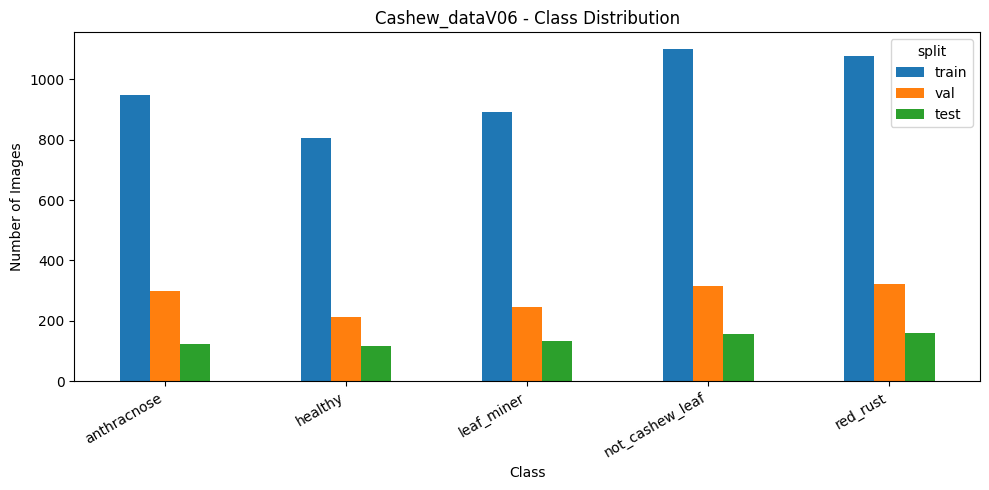

In [9]:

# ============================================================
# 07. DATASET DISTRIBUTION
# ============================================================

ax = stats_df[["train", "val", "test"]].plot(
    kind="bar",
    figsize=(10, 5)
)

ax.set_title("Cashew_dataV06 - Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of Images")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.savefig(
    DIAGNOSTIC_EXPERIMENT_ROOT / "class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [10]:

# ============================================================
# 08. FIXED FILE LISTS + TF.DATA
# ============================================================

CLASS_NAMES = EXPECTED_CLASSES
NUM_CLASSES = len(CLASS_NAMES)
AUTOTUNE = tf.data.AUTOTUNE


def split_arrays(split_name):
    df = (
        valid_df[valid_df["split"] == split_name]
        .copy()
        .reset_index(drop=True)
    )

    return (
        df["path"].to_numpy(),
        df["label"].to_numpy(dtype=np.int32),
        df
    )


train_paths, train_labels, train_meta = split_arrays("train")
val_paths, val_labels, val_meta = split_arrays("val")
test_paths, test_labels, test_meta = split_arrays("test")


def decode_image(path, label):
    image_bytes = tf.io.read_file(path)

    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE],
        method="bilinear"
    )

    return tf.cast(image, tf.float32), label


def make_dataset(paths, labels, seed, training=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=seed,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        decode_image,
        num_parallel_calls=AUTOTUNE
    )

    ds = ds.batch(
        BATCH_SIZE,
        drop_remainder=False
    )

    ds = ds.prefetch(AUTOTUNE)

    return ds


print("Fixed split:")
print("Train :", len(train_paths))
print("Val   :", len(val_paths))
print("Test  :", len(test_paths))

print("\nClass mapping:")
for idx, class_name in enumerate(CLASS_NAMES):
    print(f"{idx}: {class_name}")


Fixed split:
Train : 4825
Val   : 1395
Test  : 687

Class mapping:
0: anthracnose
1: healthy
2: leaf_miner
3: not_cashew_leaf
4: red_rust



# Model Builder

Äiá»ƒm quan trá»ng cá»§a báº£n rerun:

```python
x = backbone(x)
```

KhĂ´ng sá»­ dá»¥ng:

```python
x = backbone(x, training=True)
```

Keras sáº½ tá»± chuyá»ƒn BatchNormalization/Dropout sang training mode khi `fit()` vĂ  inference mode khi Validation/Test.

NgoĂ i ra notebook chá»‰ dĂ¹ng Ä‘Ăºng hai function:

```python
build_data_augmentation(seed)
build_densenet121_model(seed)
```


In [11]:

# ============================================================
# 09. DATA AUGMENTATION + DENSENET121 MODEL BUILDER
# ============================================================

AUGMENTATION_CONFIG = {
    "horizontal_flip": True,
    "vertical_flip": False,
    "rotation_factor": 0.04,
    "zoom_factor": 0.05,
    "translation_factor": 0.03,
    "contrast_factor": 0.08,
    "brightness": False,
    "hue_shift": False,
}


def build_data_augmentation(seed):
    return keras.Sequential(
        [
            layers.RandomFlip(
                "horizontal",
                seed=seed + 1
            ),

            layers.RandomRotation(
                factor=0.04,
                seed=seed + 2
            ),

            layers.RandomZoom(
                height_factor=(-0.05, 0.05),
                width_factor=(-0.05, 0.05),
                seed=seed + 3
            ),

            layers.RandomTranslation(
                height_factor=0.03,
                width_factor=0.03,
                seed=seed + 4
            ),

            layers.RandomContrast(
                factor=0.08,
                seed=seed + 5
            ),
        ],
        name=f"data_augmentation_seed_{seed}"
    )


def build_densenet121_model(seed):

    set_global_seed(seed)

    augmentation = build_data_augmentation(seed)

    inputs = keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="image"
    )

    # Augmentation chá»‰ hoáº¡t Ä‘á»™ng khi model á»Ÿ training mode.
    x = augmentation(inputs)

    # Scratch training: normalize áº£nh vá» [0,1].
    x = layers.Rescaling(
        1.0 / 255.0,
        name="rescale_0_1"
    )(x)

    backbone = tf.keras.applications.DenseNet121(
        include_top=False,
        weights=None,
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    backbone.trainable = True

    # ========================================================
    # QUAN TRá»ŒNG:
    # KhĂ´ng Ă©p training=True.
    # ========================================================
    x = backbone(x)

    x = layers.GlobalAveragePooling2D(
        name="global_average_pooling"
    )(x)

    x = layers.Dense(
        HEAD_UNITS,
        activation="relu",
        name="classifier_dense"
    )(x)

    x = layers.BatchNormalization(
        name="classifier_bn"
    )(x)

    x = layers.Dropout(
        HEAD_DROPOUT,
        seed=seed + 6,
        name="classifier_dropout"
    )(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax",
        name="predictions"
    )(x)

    return keras.Model(
        inputs=inputs,
        outputs=outputs,
        name=f"DenseNet121_Scratch_seed_{seed}"
    )


print("Defined:")
print("- build_data_augmentation(seed)")
print("- build_densenet121_model(seed)")


Defined:
- build_data_augmentation(seed)
- build_densenet121_model(seed)


In [12]:

# ============================================================
# 10. MODEL BUILDER SANITY CHECK
# ============================================================

# Cell nĂ y giĂºp phĂ¡t hiá»‡n lá»—i function trÆ°á»›c khi máº¥t hĂ ng giá» train.

tf.keras.backend.clear_session()
gc.collect()

sanity_seed = SEEDS[0]

with strategy.scope():
    sanity_model = build_densenet121_model(sanity_seed)

expected_output_shape = (None, NUM_CLASSES)

print("Model name        :", sanity_model.name)
print("Output shape      :", sanity_model.output_shape)
print("Total parameters  :", sanity_model.count_params())

assert sanity_model.output_shape == expected_output_shape
assert any(layer.name == "densenet121" for layer in sanity_model.layers)

print("\nSANITY CHECK PASSED.")
print("Training cell sáº½ gá»i Ä‘Ăºng build_densenet121_model(seed).")

del sanity_model
tf.keras.backend.clear_session()
gc.collect()


Global seed set to: 42
Model name        : DenseNet121_Scratch_seed_42
Output shape      : (None, 5)
Total parameters  : 7566917

SANITY CHECK PASSED.
Training cell sáº½ gá»i Ä‘Ăºng build_densenet121_model(seed).


0

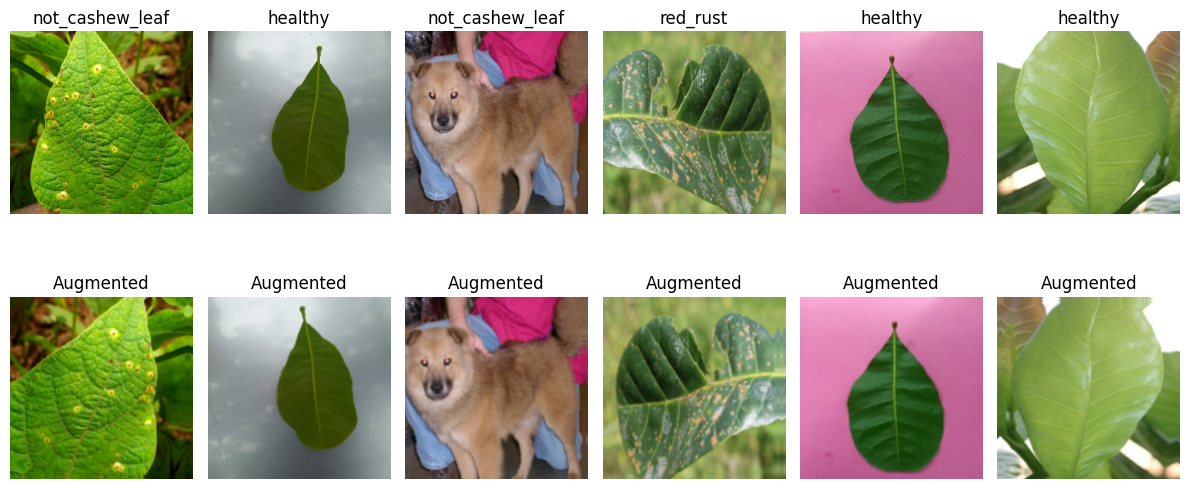

25470

In [13]:

# ============================================================
# 11. AUGMENTATION VISUAL CHECK
# ============================================================

preview_seed = SEEDS[0]

preview_ds = make_dataset(
    train_paths,
    train_labels,
    seed=preview_seed,
    training=True
)

preview_aug = build_data_augmentation(preview_seed)

for images, labels in preview_ds.take(1):

    n = min(6, int(images.shape[0]))

    plt.figure(figsize=(12, 6))

    for i in range(n):

        plt.subplot(2, 6, i + 1)
        plt.imshow(
            tf.cast(
                tf.clip_by_value(images[i], 0, 255),
                tf.uint8
            )
        )
        plt.title(CLASS_NAMES[int(labels[i])])
        plt.axis("off")

        aug_img = preview_aug(
            tf.expand_dims(images[i], 0),
            training=True
        )[0]

        plt.subplot(2, 6, i + 7)
        plt.imshow(
            tf.cast(
                tf.clip_by_value(aug_img, 0, 255),
                tf.uint8
            )
        )
        plt.title("Augmented")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

del preview_ds, preview_aug
gc.collect()


In [ ]:
if DIAGNOSTIC_ONLY:
    print('A_4 diagnostic: skipped legacy five-seed report/export cell.')
else:
    
    # ============================================================
    # 12. SAVE EXPERIMENT CONFIG
    # ============================================================
    
    experiment_config = {
        "experiment_id": EXPERIMENT_ID,
        "notebook_version": NOTEBOOK_VERSION,
        "external_holdout_protocol": {
            "archive_name": REAL_HOLDOUT_ARCHIVE_NAME,
            "archive_sha256": REAL_HOLDOUT_ARCHIVE_SHA256,
            "expected_counts": REAL_HOLDOUT_EXPECTED_COUNTS,
            "gate": "RUN_FINAL_TEST and RUN_REAL_HOLDOUT",
            "separate_from_v06_test": True,
            "macro_scope": "true classes with holdout support; currently four",
            "selection_source": "validation only",
        },
        "created_at": datetime.now().isoformat(),
    
        "dataset": {
            "version": DATASET_VERSION,
            "archive_name": DATASET_ARCHIVE_NAME,
            "archive_file_id": DATASET_ARCHIVE_FILE_ID,
            "path": str(DATASET_PATH),
            "classes": CLASS_NAMES,
            "train_images": len(train_paths),
            "val_images": len(val_paths),
            "test_images": len(test_paths),
            "total_images": len(valid_df),
            "test_set_locked": True,
        },
    
        "model": {
            "name": MODEL_NAME,
            "training_mode": TRAINING_MODE,
            "weights": PRETRAINED_WEIGHTS,
            "include_top": False,
            "input_size": [IMG_SIZE, IMG_SIZE, 3],
            "head_units": HEAD_UNITS,
            "head_dropout": HEAD_DROPOUT,
            "backbone_call": "x = backbone(x)",
            "forced_training_true": False,
        },
    
        "training": {
            "seeds": SEEDS,
            "batch_size": BATCH_SIZE,
            "max_epochs": MAX_EPOCHS,
            "optimizer": "Adam",
            "initial_learning_rate": INITIAL_LR,
            "loss": "SparseCategoricalCrossentropy",
            "class_weight": None,
        },
    
        "augmentation": AUGMENTATION_CONFIG,
    
        "callbacks": {
            "checkpoint_monitor": "val_loss",
            "checkpoint_mode": "min",
            "checkpoint_type": "weights_only",
            "early_stopping_patience": EARLY_STOPPING_PATIENCE,
            "reduce_lr_patience": REDUCE_LR_PATIENCE,
            "reduce_lr_factor": REDUCE_LR_FACTOR,
            "min_lr": MIN_LR,
        },
    
        "test_protocol": {
            "run_final_test": RUN_FINAL_TEST,
            "final_test_completed": False,
            "same_locked_test_for_all_seeds": True,
            "do_not_select_best_seed_on_test": True,
            "summary": "mean Â± sample standard deviation (ddof=1)",
        },
    
    
    "deployment_protocol": {
        "selection_source": "validation only",
        "selection_metric": "val_macro_f1",
        "tie_break": "lower val_loss",
        "test_used_for_selection": False,
    },
    
    "figure_protocol": {
        "comparison_layout": "panel",
        "training_curves": "2 rows x 5 seed columns",
        "confusion_matrices": "1 row x 5 seed columns",
    },
    
    "archive": {
        "full_archive": f"{EXPERIMENT_ID}_FULL.zip",
        "analysis_archive": f"{EXPERIMENT_ID}_ANALYSIS.zip",
        "google_drive_target_url": DRIVE_TARGET_URL,
        "google_drive_target_folder_id": DRIVE_TARGET_FOLDER_ID,
    },
    
        "hardware": {
            "gpu_count": len(gpus),
            "strategy": strategy.__class__.__name__,
            "replicas": strategy.num_replicas_in_sync,
        },
    }
    
    config_path = OUT_DIR / "experiment_config.json"
    
    if config_path.exists():
        saved_config = json.loads(config_path.read_text(encoding="utf-8"))
        # Compare frozen training/Validation sections before reusing saved results.
        compare_keys = ("model", "training", "augmentation", "callbacks")
        if not DIAGNOSTIC_ONLY:
            compare_keys = ("dataset",) + compare_keys
        for key in compare_keys:
            if key not in saved_config or saved_config[key] != experiment_config[key]:
                raise ValueError(f"Saved {key} differs from this notebook. Restore the frozen configuration.")
        experiment_config = saved_config
    else:
        config_path.write_text(
            json.dumps(experiment_config, indent=2, ensure_ascii=False), encoding="utf-8"
        )
    
    print("Saved:", config_path)
    
    
    drive_target_path = OUT_DIR / "drive_target.json"
    drive_target_path.write_text(
        json.dumps(
            {
                "folder_url": DRIVE_TARGET_URL,
                "folder_id": DRIVE_TARGET_FOLDER_ID,
                "archive_name": f"{EXPERIMENT_ID}_FULL.zip",
            },
            indent=2,
        ),
        encoding="utf-8",
    )
    print("Saved:", drive_target_path)


## Locked real-world holdout (external Test)

Upload this notebook alone to Colab: the shared evaluator is embedded below, so no
additional Python module upload is necessary. On Colab the ZIP is read from
`MyDrive/Cashew_Leaf_model_result/Dataset/RL_Cashew_holdout.zip`.
Set `REAL_HOLDOUT_ARCHIVE_OVERRIDE` if your mounted location differs.
This preflight runs only when both Test flags permit it, before any Test prediction.

When Final Test is already enabled, this data-only check runs before costly training.
If enabling Test after training, run this preflight cell again before the Test drivers.


In [ ]:
"""Locked external classification evaluation; embedded in standalone notebooks.

This file has no training code. Holdout labels never select checkpoints or seeds.
"""

import hashlib
import json
import os
import stat
import time
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import f1_score, precision_score, recall_score


REAL_HOLDOUT_HELPER_VERSION = "006.1"
REAL_HOLDOUT_CMAP = LinearSegmentedColormap.from_list(
    "real_holdout_readable_blues", ["#ffffff", "#dbeafe", "#93c5fd"]
)


def holdout_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest().upper()


def resolve_holdout_archive(archive_name, override=None):
    if override is not None:
        candidate = Path(override)
        if not candidate.is_file():
            raise FileNotFoundError(candidate)
        return candidate
    if Path("/content/drive/MyDrive").is_dir():
        candidate = Path("/content/drive/MyDrive/Cashew_Leaf_model_result/Dataset") / archive_name
        if candidate.is_file():
            return candidate
    if os.name == "nt":
        candidate = Path(r"D:\Study\KhoaLuanTotNghiep\Dataset") / archive_name
        if candidate.is_file():
            return candidate
    if Path("/kaggle/input").is_dir():
        candidates = sorted(Path("/kaggle/input").rglob(archive_name))
        if len(candidates) == 1:
            return candidates[0]
    raise FileNotFoundError(
        f"Cannot uniquely locate {archive_name}. Set REAL_HOLDOUT_ARCHIVE_OVERRIDE "
        "to the mounted ZIP path; on Colab add the supplied Dataset folder to My Drive."
    )


def prepare_real_holdout(archive_path, extraction_dir, class_names, expected_sha256,
                         expected_counts, reference_rows, audit_dir):
    """Verify the frozen archive, labels, decoding and byte overlap with V05.

    reference_rows: dictionaries with path/split and optional existing sha256.
    Exact-byte checking does not establish independence of near-duplicate photos.
    """
    archive_path, extraction_dir, audit_dir = map(Path, (archive_path, extraction_dir, audit_dir))
    actual_hash = holdout_sha256(archive_path)
    if actual_hash != expected_sha256.upper():
        raise ValueError(f"Holdout archive changed: {actual_hash}; expected {expected_sha256}.")
    marker = extraction_dir / ".archive_sha256"
    if extraction_dir.exists():
        if not marker.is_file() or marker.read_text(encoding="utf-8").strip() != actual_hash:
            raise FileExistsError(f"Unverified extraction: {extraction_dir}; choose a new directory.")
    else:
        with zipfile.ZipFile(archive_path) as archive:
            resolved_root = extraction_dir.resolve()
            for member in archive.infolist():
                target = (extraction_dir / member.filename.replace("\\", "/")).resolve()
                is_symlink = stat.S_ISLNK(member.external_attr >> 16)
                if is_symlink or (target != resolved_root and resolved_root not in target.parents):
                    raise ValueError(f"Unsafe ZIP member: {member.filename}")
            extraction_dir.mkdir(parents=True)
            archive.extractall(extraction_dir)
        marker.write_text(actual_hash, encoding="utf-8")

    dataset_root = extraction_dir / "RL_Cashew_holdout"
    if not dataset_root.is_dir():
        raise FileNotFoundError(dataset_root)
    found_classes = sorted(p.name for p in dataset_root.iterdir() if p.is_dir())
    if found_classes != sorted(expected_counts) or not set(found_classes).issubset(class_names):
        raise ValueError(f"Unexpected holdout class folders: {found_classes}")
    rows = []
    for label, name in enumerate(class_names):
        class_dir = dataset_root / name
        files = sorted(p for p in class_dir.rglob("*") if p.is_file()) if class_dir.is_dir() else []
        if len(files) != expected_counts.get(name, 0):
            raise ValueError(f"Unexpected holdout count for {name}: {len(files)}")
        for image_path in files:
            if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}:
                raise ValueError(f"Unsupported holdout image: {image_path}")
            with Image.open(image_path) as image:
                image.verify()
            with Image.open(image_path) as image:
                image.convert("RGB").load()
            rows.append({"path": str(image_path), "relative_path": image_path.relative_to(dataset_root).as_posix(),
                         "class": name, "label": label, "sha256": holdout_sha256(image_path)})
    manifest = pd.DataFrame(rows)
    if manifest.empty or manifest["sha256"].duplicated().any():
        raise ValueError("Holdout is empty or contains duplicate image bytes.")
    # A marker alone is insufficient: verify cached extraction bytes against the ZIP.
    with zipfile.ZipFile(archive_path) as frozen_archive:
        for row in rows:
            digest = hashlib.sha256()
            with frozen_archive.open("RL_Cashew_holdout/" + row["relative_path"]) as stream:
                for block in iter(lambda: stream.read(1024 * 1024), b""):
                    digest.update(block)
            if digest.hexdigest().upper() != row["sha256"]:
                raise ValueError(f"Cached holdout extraction changed: {row['relative_path']}")
    audit_dir.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(audit_dir / "dataset_manifest.csv", index=False)

    references = list(reference_rows)
    if not references or not {"train", "val", "test"}.issubset({r["split"] for r in references}):
        raise ValueError("Overlap audit needs the full train/val/test V05 reference manifest.")
    holdout_hashes = set(manifest["sha256"])
    overlaps = []
    reference_digest = hashlib.sha256()
    for row in references:
        digest = row.get("sha256") or holdout_sha256(row["path"])
        digest = digest.upper()
        identity = row.get("relative_path", str(row["path"]))
        reference_digest.update(f"{row['split']}\0{identity}\0{digest}\n".encode("utf-8"))
        if digest in holdout_hashes:
            overlaps.append({"reference_path": str(row["path"]), "split": row["split"], "sha256": digest})
    present = [name for name in class_names if expected_counts.get(name, 0) > 0]
    audit = {"archive_sha256": actual_hash, "archive_name": archive_path.name,
             "manifest_sha256": hashlib.sha256(manifest[["relative_path", "class", "label", "sha256"]]
                 .to_csv(index=False).encode()).hexdigest(),
             "counts": {name: expected_counts.get(name, 0) for name in class_names},
             "images": len(manifest), "present_classes": present,
             "unsupported_classes": [name for name in class_names if name not in present],
             "reference_images_checked": len(references), "reference_fingerprint": reference_digest.hexdigest(),
             "byte_overlap_count": len(overlaps), "byte_overlaps": overlaps,
             "limitation": "Byte audit only; near-duplicate photos and shared trees/sessions need a separate audit."}
    (audit_dir / "dataset_audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
    if overlaps:
        raise ValueError("Real holdout overlaps V05 by exact bytes; inspect dataset_audit.json before evaluation.")
    print("Real holdout:", len(manifest), "images; present classes:", present)
    print("Not evaluated (no true examples):", audit["unsupported_classes"])
    return manifest, audit


def save_real_holdout_seed(manifest, probabilities, class_names, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    probabilities = np.asarray(probabilities, dtype=np.float64)
    if probabilities.shape != (len(manifest), len(class_names)) or not np.isfinite(probabilities).all():
        raise ValueError("Holdout predictions have invalid shape or non-finite values.")
    if (probabilities < 0).any() or not np.allclose(probabilities.sum(axis=1), 1, atol=1e-5):
        raise ValueError("Holdout evaluator expects probabilities, not logits.")
    y_true = manifest["label"].to_numpy(dtype=np.int32)
    y_pred = probabilities.argmax(axis=1)
    present_ids = sorted(set(y_true.tolist()))
    all_ids = list(range(len(class_names)))
    result = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_precision_present_classes": float(precision_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_recall_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "macro_f1_present_classes": float(f1_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "balanced_accuracy_present_classes": float(recall_score(y_true, y_pred, labels=present_ids, average="macro", zero_division=0)),
        "images": len(manifest), "macro_class_count": len(present_ids),
    }
    report = pd.DataFrame(classification_report(y_true, y_pred, labels=all_ids,
        target_names=class_names, output_dict=True, zero_division=0)).transpose()
    per_class = report.loc[class_names, ["precision", "recall", "f1-score", "support"]].copy()
    per_class["evaluated"] = per_class["support"] > 0
    # No evidence for unsupported true classes: don't present placeholder zeros as performance.
    per_class.loc[~per_class["evaluated"], ["precision", "recall", "f1-score"]] = np.nan
    per_class.to_csv(output_dir / "per_class_metrics.csv", index_label="class")
    readable_report = per_class.copy()
    readable_report["scope"] = np.where(readable_report["evaluated"], "true class present", "not evaluated: zero true support")
    readable_report.loc["macro avg (present classes)"] = [
        result["macro_precision_present_classes"], result["macro_recall_present_classes"],
        result["macro_f1_present_classes"], len(manifest), True,
        f"{len(present_ids)} supported true classes only",
    ]
    readable_report.loc["weighted avg"] = [
        report.loc["weighted avg", "precision"], report.loc["weighted avg", "recall"],
        report.loc["weighted avg", "f1-score"], len(manifest), True, "weighted by true support",
    ]
    readable_report.to_csv(output_dir / "classification_report.csv", index_label="class")
    predictions = manifest[["relative_path", "class", "label"]].copy()
    predictions["predicted_label"] = y_pred
    predictions["predicted_class"] = [class_names[i] for i in y_pred]
    predictions["confidence"] = probabilities.max(axis=1)
    predictions["correct"] = y_true == y_pred
    for label, name in enumerate(class_names):
        predictions[f"probability_{name}"] = probabilities[:, label]
    predictions.to_csv(output_dir / "predictions.csv", index=False)
    matrix = confusion_matrix(y_true, y_pred, labels=all_ids)
    for normalized, suffix in ((False, ""), (True, "_normalized")):
        values = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1) if normalized else matrix
        pd.DataFrame(values, index=class_names, columns=class_names).to_csv(output_dir / f"confusion_matrix{suffix}.csv")
        fig, ax = plt.subplots(figsize=(9, 8), facecolor="white")
        ax.set_facecolor("white")
        ax.imshow(values, cmap=REAL_HOLDOUT_CMAP, vmin=0,
                  vmax=1 if normalized else max(int(matrix.max()), 1))
        ax.set_xticks(all_ids, class_names, rotation=40, ha="right", color="black")
        ax.set_yticks(all_ids, class_names, color="black")
        ax.set_xlabel("Predicted class", color="black")
        ax.set_ylabel("True class", color="black")
        ax.set_title("Real holdout" + (" (row normalized)" if normalized else ""), color="black")
        for row in all_ids:
            for col in all_ids:
                text = f"{values[row, col]:.2f}" if normalized else str(int(values[row, col]))
                if normalized and row not in present_ids:
                    text = "N/A"
                ax.text(col, row, text, ha="center", va="center", color="black")
        fig.tight_layout()
        fig.savefig(output_dir / f"confusion_matrix{suffix}.png", dpi=180)
        plt.close(fig)
    (output_dir / "metrics.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    return result


def evaluate_real_holdout(manifest, audit, class_names, seeds, validation_results,
                          checkpoints, load_model, make_dataset, clear_session,
                          output_dir, outputs_are_logits=False):
    """Freeze all checkpoints and validation selection BEFORE any prediction.

    Completed evaluations are read back, not repeated. Interrupted evaluations
    may resume only with the same checkpoint, validation and archive fingerprints.
    """
    output_dir = Path(output_dir)
    seeds = [int(seed) for seed in seeds]
    validation_results = validation_results.copy()
    if validation_results["seed"].tolist() != seeds:
        raise ValueError("Holdout evaluation requires completed, ordered validation for every seed.")
    if not np.isfinite(validation_results[["val_macro_f1", "val_loss"]].to_numpy()).all():
        raise ValueError("Validation selection metrics are incomplete.")
    ranked = validation_results.sort_values(["val_macro_f1", "val_loss", "seed"], ascending=[False, True, True])
    deployment_seed = int(ranked.iloc[0]["seed"])
    checkpoint_hashes = {str(seed): holdout_sha256(checkpoints[seed]) for seed in seeds}
    lock = {"helper_version": REAL_HOLDOUT_HELPER_VERSION, "archive_sha256": audit["archive_sha256"],
            "manifest_sha256": audit["manifest_sha256"],
            "reference_fingerprint": audit["reference_fingerprint"], "seeds": seeds,
            "checkpoint_sha256": checkpoint_hashes, "deployment_seed": deployment_seed,
            # Canonical float precision avoids false lock changes on CSV reload.
            "validation_sha256": hashlib.sha256(validation_results.to_csv(index=False, float_format="%.12g").encode()).hexdigest(),
            "model_classes": class_names, "macro_classes": audit["present_classes"],
            "selection_source": "validation only; macro F1, val_loss, seed tie-break",
            "outputs_are_logits": outputs_are_logits}
    lock_path = output_dir / "evaluation_lock.json"
    if lock_path.exists():
        if json.loads(lock_path.read_text(encoding="utf-8")) != lock:
            raise ValueError("Holdout lock changed. Do not retune using holdout or overwrite its results.")
    else:
        output_dir.mkdir(parents=True, exist_ok=True)
        lock_path.write_text(json.dumps(lock, indent=2), encoding="utf-8")
    aggregate_dir = output_dir / "aggregate"
    aggregate_dir.mkdir(exist_ok=True)
    results_path = aggregate_dir / "real_holdout_results_5seeds.csv"
    if (output_dir / "evaluation_completed.json").exists():
        print("Real holdout already completed; reading frozen results, not running predictions again.")
        return pd.read_csv(results_path)
    result_rows = []
    for seed in seeds:
        seed_dir = output_dir / f"seed_{seed}"
        completed_path = seed_dir / "evaluation_completed.json"
        if completed_path.exists():
            row = json.loads(completed_path.read_text(encoding="utf-8"))
        else:
            clear_session()
            model = load_model(seed)
            dataset = make_dataset(manifest)
            start = time.perf_counter()
            scores = np.asarray(model.predict(dataset, verbose=0))
            prediction_seconds = time.perf_counter() - start
            if outputs_are_logits:
                exponentials = np.exp(scores - scores.max(axis=1, keepdims=True))
                scores = exponentials / exponentials.sum(axis=1, keepdims=True)
            row = {"seed": seed, **save_real_holdout_seed(manifest, scores, class_names, seed_dir),
                   "prediction_seconds_including_input_pipeline": prediction_seconds}
            completed_path.write_text(json.dumps(row, indent=2), encoding="utf-8")
            del model, scores, dataset
            clear_session()
        result_rows.append(row)
    results = pd.DataFrame(result_rows)
    results.to_csv(results_path, index=False)
    metric_columns = [c for c in results if c not in {"seed", "images", "macro_class_count"}]
    results[metric_columns].agg(["mean", "std"]).transpose().to_csv(aggregate_dir / "real_holdout_mean_std.csv")
    per_class = pd.concat([pd.read_csv(output_dir / f"seed_{seed}" / "per_class_metrics.csv")
                          .assign(seed=seed) for seed in seeds], ignore_index=True)
    per_class.groupby("class")[["precision", "recall", "f1-score"]].agg(["mean", "std"]).to_csv(
        aggregate_dir / "per_class_real_holdout_mean_std.csv")
    deployment_result = next(row for row in result_rows if row["seed"] == deployment_seed)
    (aggregate_dir / "deployment_seed_result.json").write_text(json.dumps({
        "selection_source": "validation only, fixed before holdout", "result": deployment_result,
    }, indent=2), encoding="utf-8")
    (output_dir / "evaluation_completed.json").write_text(json.dumps({
        "completed_at_utc": datetime.now(timezone.utc).isoformat(),
        "note": "No model or seed selection on holdout. SD measures training-seed variability, not sampling uncertainty.",
    }, indent=2), encoding="utf-8")
    print("Real holdout results (macro metrics over supported true classes only):")
    print(results)
    return results

# --- Notebook-specific real holdout preflight (no prediction/training here) ---
if RUN_FINAL_TEST and RUN_REAL_HOLDOUT:
    holdout_archive = resolve_holdout_archive(REAL_HOLDOUT_ARCHIVE_NAME, REAL_HOLDOUT_ARCHIVE_OVERRIDE)
    holdout_reference_rows = valid_df.assign(
        relative_path=valid_df["path"].map(lambda path: Path(path).relative_to(DATASET_PATH).as_posix())
    ).to_dict("records")
    holdout_out_dir = OUT_DIR / "real_holdout"
    # Use runtime-local storage, not the Drive result directory, for images.
    if Path("/content").is_dir():
        holdout_extract_dir = Path("/content/real_holdout_006") / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    elif Path("/kaggle/working").is_dir():
        holdout_extract_dir = Path("/kaggle/working/real_holdout_006") / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    else:
        import tempfile
        holdout_extract_dir = Path(tempfile.gettempdir()) / "cashew_real_holdout_006" / REAL_HOLDOUT_ARCHIVE_SHA256[:12]
    real_holdout_manifest, real_holdout_audit = prepare_real_holdout(
        holdout_archive, holdout_extract_dir, CLASS_NAMES,
        REAL_HOLDOUT_ARCHIVE_SHA256, REAL_HOLDOUT_EXPECTED_COUNTS,
        holdout_reference_rows, holdout_out_dir,
    )
else:
    print("Real-world holdout remains locked; no holdout extraction/evaluation runs.")



# Train 5 Seeds

Cell tiáº¿p theo cháº¡y láº§n lÆ°á»£t:

```text
42 â†’ 123 â†’ 2026 â†’ 3407 â†’ 7777
```

Má»—i seed:
- táº¡o model má»›i hoĂ n toĂ n;
- train cĂ¹ng má»™t split;
- lÆ°u `best.weights.h5` theo `val_loss`;
- lÆ°u `history.csv`;
- lÆ°u learning curves;
- sau train, **reload Ä‘Ăºng best weights**;
- Ä‘Ă¡nh giĂ¡ Validation vĂ  lÆ°u Macro-F1 / Balanced Accuracy / confusion matrix.

Test **khĂ´ng Ä‘Æ°á»£c Ä‘á»c** trong cell nĂ y.


In [ ]:
if DIAGNOSTIC_ONLY:
    print('A_4 diagnostic: skipped legacy five-seed report/export cell.')
else:
    
    # ============================================================
    # 13. TRAIN ALL 5 SEEDS
    # ============================================================
    
    training_rows = []
    validation_rows = []
    
    for run_index, seed in enumerate(SEEDS if RUN_TRAINING else [], start=1):
    
        print("\n" + "=" * 80)
        print(f"RUN {run_index}/{len(SEEDS)} - SEED {seed}")
        print("=" * 80)
    
        tf.keras.backend.clear_session()
        gc.collect()
        set_global_seed(seed)
    
        # --------------------------------------------------------
        # Folders
        # --------------------------------------------------------
    
        seed_dir = OUT_DIR / f"seed_{seed}"
    
        checkpoint_dir = seed_dir / "checkpoints"
        log_dir = seed_dir / "logs"
        figure_dir = seed_dir / "figures"
        validation_dir = seed_dir / "validation"
    
        for folder in [
            checkpoint_dir,
            log_dir,
            figure_dir,
            validation_dir,
        ]:
            folder.mkdir(parents=True, exist_ok=True)
    
        best_weights_path = (
            checkpoint_dir /
            f"DENSENET121_SCRATCH_seed_{seed}_best.weights.h5"
        )
        if best_weights_path.exists() or (log_dir / "history.csv").exists():
            raise FileExistsError(f"Refusing to overwrite training outputs for seed {seed}.")
    
        # --------------------------------------------------------
        # Datasets
        # --------------------------------------------------------
    
        train_ds = make_dataset(
            train_paths,
            train_labels,
            seed=seed,
            training=True
        )
    
        val_ds = make_dataset(
            val_paths,
            val_labels,
            seed=seed,
            training=False
        )
    
        # --------------------------------------------------------
        # Build + compile
        # --------------------------------------------------------
    
        with strategy.scope():
    
            # CHá»ˆ dĂ¹ng function nĂ y.
            model = build_densenet121_model(seed)
    
            model.compile(
                optimizer=tf.keras.optimizers.Adam(
                    learning_rate=INITIAL_LR
                ),
                loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                metrics=["accuracy"],
            )
    
        # --------------------------------------------------------
        # Model summary
        # --------------------------------------------------------
    
        summary_lines = []
    
        model.summary(
            print_fn=lambda line: summary_lines.append(line)
        )
    
        (
            seed_dir /
            "model_summary.txt"
        ).write_text(
            "\n".join(summary_lines),
            encoding="utf-8"
        )
    
        total_params = int(model.count_params())
    
        trainable_params = int(
            np.sum([
                np.prod(v.shape)
                for v in model.trainable_weights
            ])
        )
    
        non_trainable_params = int(
            total_params - trainable_params
        )
    
        # --------------------------------------------------------
        # Callbacks
        # --------------------------------------------------------
    
        callbacks = [
    
            tf.keras.callbacks.ModelCheckpoint(
                filepath=str(best_weights_path),
                monitor="val_loss",
                mode="min",
                save_best_only=True,
                save_weights_only=True,
                verbose=1,
            ),
    
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                mode="min",
                patience=EARLY_STOPPING_PATIENCE,
                restore_best_weights=True,
                verbose=1,
            ),
    
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor="val_loss",
                mode="min",
                factor=REDUCE_LR_FACTOR,
                patience=REDUCE_LR_PATIENCE,
                min_lr=MIN_LR,
                verbose=1,
            ),
    
            tf.keras.callbacks.CSVLogger(
                str(log_dir / "training_log.csv")
            ),
        ]
    
        # --------------------------------------------------------
        # Train
        # --------------------------------------------------------
    
        start_time = time.perf_counter()
    
        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=MAX_EPOCHS,
            callbacks=callbacks,
            verbose=1,
        )
    
        training_time_seconds = time.perf_counter() - start_time
    
        # --------------------------------------------------------
        # History
        # --------------------------------------------------------
    
        history_df = pd.DataFrame(history.history)
    
        history_df.insert(
            0,
            "epoch",
            np.arange(1, len(history_df) + 1)
        )
    
        history_df.to_csv(
            log_dir / "history.csv",
            index=False
        )
    
        actual_epochs = len(history_df)
    
        best_epoch = int(
            np.argmin(history.history["val_loss"])
        ) + 1
    
        best_val_loss_history = float(
            np.min(history.history["val_loss"])
        )
    
        best_val_accuracy_history = float(
            history.history["val_accuracy"][best_epoch - 1]
        )
    
        # --------------------------------------------------------
        # Curves
        # --------------------------------------------------------
    
        plt.figure(figsize=(8, 5))
    
        plt.plot(
            history_df["epoch"],
            history_df["accuracy"],
            label="Train"
        )
    
        plt.plot(
            history_df["epoch"],
            history_df["val_accuracy"],
            label="Validation"
        )
    
        plt.axvline(
            best_epoch,
            linestyle="--",
            label=f"Best epoch = {best_epoch}"
        )
    
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.title(f"DenseNet121 Scratch - Seed {seed} - Accuracy")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
    
        plt.savefig(
            figure_dir / "accuracy_curve.png",
            dpi=200,
            bbox_inches="tight"
        )
    
        plt.close()
    
        plt.figure(figsize=(8, 5))
    
        plt.plot(
            history_df["epoch"],
            history_df["loss"],
            label="Train"
        )
    
        plt.plot(
            history_df["epoch"],
            history_df["val_loss"],
            label="Validation"
        )
    
        plt.axvline(
            best_epoch,
            linestyle="--",
            label=f"Best epoch = {best_epoch}"
        )
    
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title(f"DenseNet121 Scratch - Seed {seed} - Loss")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
    
        plt.savefig(
            figure_dir / "loss_curve.png",
            dpi=200,
            bbox_inches="tight"
        )
    
        plt.close()
    
        # --------------------------------------------------------
        # IMPORTANT:
        # Reload exactly the checkpoint chosen by minimum val_loss.
        # --------------------------------------------------------
    
        model.load_weights(best_weights_path)
    
        # --------------------------------------------------------
        # Validation evaluation
        # --------------------------------------------------------
    
        val_loss, val_accuracy = model.evaluate(
            val_ds,
            verbose=0
        )
    
        y_val_true = []
        y_val_prob = []
    
        for images, labels in val_ds:
    
            probs = model.predict(
                images,
                verbose=0
            )
    
            y_val_prob.append(probs)
            y_val_true.append(labels.numpy())
    
        y_val_true = np.concatenate(y_val_true)
        y_val_prob = np.concatenate(y_val_prob)
        y_val_pred = np.argmax(y_val_prob, axis=1)
        y_val_conf = np.max(y_val_prob, axis=1)
    
        val_metrics = {
            "seed": seed,
            "val_loss": float(val_loss),
            "val_accuracy": float(
                accuracy_score(y_val_true, y_val_pred)
            ),
            "val_macro_precision": float(
                precision_score(
                    y_val_true,
                    y_val_pred,
                    average="macro",
                    zero_division=0
                )
            ),
            "val_macro_recall": float(
                recall_score(
                    y_val_true,
                    y_val_pred,
                    average="macro",
                    zero_division=0
                )
            ),
            "val_macro_f1": float(
                f1_score(
                    y_val_true,
                    y_val_pred,
                    average="macro",
                    zero_division=0
                )
            ),
            "val_balanced_accuracy": float(
                balanced_accuracy_score(
                    y_val_true,
                    y_val_pred
                )
            ),
        }
    
        validation_rows.append(val_metrics)
    
        # --------------------------------------------------------
        # Validation classification report
        # --------------------------------------------------------
    
        val_report_df = pd.DataFrame(
            classification_report(
                y_val_true,
                y_val_pred,
                target_names=CLASS_NAMES,
                output_dict=True,
                zero_division=0,
            )
        ).transpose()
    
        val_report_df.to_csv(
            validation_dir /
            "classification_report.csv"
        )
    
        # --------------------------------------------------------
        # Validation confusion matrix
        # --------------------------------------------------------
    
        val_cm = confusion_matrix(
            y_val_true,
            y_val_pred
        )
    
        val_cm_norm = confusion_matrix(
            y_val_true,
            y_val_pred,
            normalize="true"
        )
    
        pd.DataFrame(
            val_cm,
            index=CLASS_NAMES,
            columns=CLASS_NAMES
        ).to_csv(
            validation_dir /
            "confusion_matrix.csv"
        )
    
        pd.DataFrame(
            val_cm_norm,
            index=CLASS_NAMES,
            columns=CLASS_NAMES
        ).to_csv(
            validation_dir /
            "confusion_matrix_normalized.csv"
        )
    
        fig, ax = plt.subplots(figsize=(8, 7))
    
        matrix_display = ConfusionMatrixDisplay(
            confusion_matrix=val_cm,
            display_labels=CLASS_NAMES
        ).plot(
            ax=ax,
            cmap=MATRIX_CMAP,
            values_format="d",
            colorbar=False
        )
        for label in matrix_display.text_.ravel():
            label.set_color("black")
    
        plt.title(
            f"Validation Confusion Matrix - Seed {seed}"
        )
    
        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()
    
        plt.savefig(
            validation_dir /
            "confusion_matrix.png",
            dpi=200,
            bbox_inches="tight"
        )
    
        plt.close()
    
        # --------------------------------------------------------
        # Validation predictions
        # --------------------------------------------------------
    
        val_predictions_df = pd.DataFrame({
            "filename": val_meta["path"],
            "true_label": [
                CLASS_NAMES[int(i)]
                for i in y_val_true
            ],
            "predicted_label": [
                CLASS_NAMES[int(i)]
                for i in y_val_pred
            ],
            "confidence": y_val_conf,
            "correct": y_val_true == y_val_pred,
        })
    
        val_predictions_df.to_csv(
            validation_dir /
            "predictions.csv",
            index=False
        )
    
        # --------------------------------------------------------
        # Training summary
        # --------------------------------------------------------
    
        row = {
            "seed": seed,
            "actual_epochs": actual_epochs,
            "best_epoch": best_epoch,
            "best_val_loss_history": best_val_loss_history,
            "best_val_accuracy_history": best_val_accuracy_history,
            "checkpoint_val_loss": float(val_loss),
            "checkpoint_val_accuracy": float(val_metrics["val_accuracy"]),
            "checkpoint_val_macro_f1": float(val_metrics["val_macro_f1"]),
            "checkpoint_val_balanced_accuracy": float(
                val_metrics["val_balanced_accuracy"]
            ),
            "training_time_seconds": float(training_time_seconds),
            "total_parameters": total_params,
            "trainable_parameters": trainable_params,
            "non_trainable_parameters": non_trainable_params,
            "best_weights_path": str(best_weights_path),
            "best_weights_size_mb": float(
                best_weights_path.stat().st_size /
                (1024 ** 2)
            ),
        }
    
        training_rows.append(row)
    
        (
            seed_dir /
            "training_summary.json"
        ).write_text(
            json.dumps(
                row,
                indent=2
            ),
            encoding="utf-8"
        )
    
        print("\nSeed summary:")
        print(json.dumps(row, indent=2))
    
        # --------------------------------------------------------
        # Cleanup
        # --------------------------------------------------------
    
        del model
        del train_ds
        del val_ds
        del history
    
        tf.keras.backend.clear_session()
        gc.collect()
    
    
    if RUN_TRAINING:
        training_summary_df = pd.DataFrame(training_rows)
        validation_results_df = pd.DataFrame(validation_rows)
    else:
        training_summary_df = pd.read_csv(AGGREGATE_DIR / "training_summary_5seeds.csv")
        validation_results_df = pd.read_csv(AGGREGATE_DIR / "validation_results_5seeds.csv")
        if training_summary_df["seed"].tolist() != SEEDS or validation_results_df["seed"].tolist() != SEEDS:
            raise ValueError("Saved training/validation results must contain all configured seeds.")
    
    if RUN_TRAINING:
        training_summary_df.to_csv(AGGREGATE_DIR / "training_summary_5seeds.csv", index=False)
        validation_results_df.to_csv(AGGREGATE_DIR / "validation_results_5seeds.csv", index=False)
    
    # Wall time around model.fit includes epoch validation and callbacks.
    training_times = training_summary_df["training_time_seconds"]
    training_time_summary = pd.DataFrame({
        "metric": ["training_time_seconds", "training_time_minutes"],
        "mean": [training_times.mean(), training_times.mean() / 60],
        "std": [training_times.std(ddof=1), training_times.std(ddof=1) / 60],
        "total": [training_times.sum(), training_times.sum() / 60],
    })
    training_time_summary.to_csv(AGGREGATE_DIR / "training_time_mean_std_summary.csv", index=False)
    print("\nTraining time across seeds:")
    display(training_time_summary)
    
    print("\nTraining summary:")
    display(training_summary_df)
    
    print("\nValidation metrics:")
    display(validation_results_df)


In [ ]:
if DIAGNOSTIC_ONLY:
    print('A_4 diagnostic: skipped legacy five-seed report/export cell.')
else:
    
    # ============================================================
    # 14. VALIDATION MEAN Â± STD
    # ============================================================
    
    validation_metrics_to_summarize = [
        "val_accuracy",
        "val_macro_precision",
        "val_macro_recall",
        "val_macro_f1",
        "val_balanced_accuracy",
    ]
    
    validation_summary_rows = []
    
    for metric in validation_metrics_to_summarize:
    
        values = validation_results_df[metric]
    
        validation_summary_rows.append({
            "metric": metric,
            "mean": float(values.mean()),
            "std": float(values.std(ddof=1)),
            "report": (
                f"{values.mean()*100:.2f} Â± "
                f"{values.std(ddof=1)*100:.2f}%"
            ),
        })
    
    validation_mean_std_df = pd.DataFrame(
        validation_summary_rows
    )
    
    display(validation_mean_std_df)
    
    validation_mean_std_df.to_csv(
        AGGREGATE_DIR /
        "validation_mean_std_summary.csv",
        index=False
    )
    
    print("\nBest epoch across seeds:")
    print(
        f"{training_summary_df['best_epoch'].mean():.2f} Â± "
        f"{training_summary_df['best_epoch'].std(ddof=1):.2f}"
    )


In [ ]:
if DIAGNOSTIC_ONLY:
    print('A_4 diagnostic: skipped legacy five-seed report/export cell.')
else:
    
    # ============================================================
    # 14B. PAPER-STYLE 5-SEED VALIDATION PANELS
    # ============================================================
    
    # ------------------------------------------------------------
    # A. Training curves: 2 rows x 5 seed columns
    #    Row 1 = Accuracy, Row 2 = Loss
    # ------------------------------------------------------------
    
    histories = {}
    for seed in SEEDS:
        history_path = OUT_DIR / f"seed_{seed}" / "logs" / "history.csv"
        histories[seed] = pd.read_csv(history_path)
    
    fig, axes = plt.subplots(
        2,
        len(SEEDS),
        figsize=(27, 9),
        sharey="row"
    )
    
    all_losses = []
    for seed in SEEDS:
        all_losses.extend(histories[seed]["loss"].tolist())
        all_losses.extend(histories[seed]["val_loss"].tolist())
    
    loss_upper = max(all_losses) * 1.05
    
    for col, seed in enumerate(SEEDS):
        hist = histories[seed]
        best_epoch = int(hist.loc[hist["val_loss"].idxmin(), "epoch"])
    
        axes[0, col].plot(hist["epoch"], hist["accuracy"], label="Train")
        axes[0, col].plot(hist["epoch"], hist["val_accuracy"], label="Validation")
        axes[0, col].axvline(best_epoch, linestyle="--")
        axes[0, col].set_title(f"Seed {seed}")
        axes[0, col].set_xlabel("Epoch")
        axes[0, col].set_ylim(0, 1)
        axes[0, col].grid(alpha=0.25)
    
        axes[1, col].plot(hist["epoch"], hist["loss"], label="Train")
        axes[1, col].plot(hist["epoch"], hist["val_loss"], label="Validation")
        axes[1, col].axvline(best_epoch, linestyle="--")
        axes[1, col].set_xlabel("Epoch")
        axes[1, col].set_ylim(0, loss_upper)
        axes[1, col].grid(alpha=0.25)
    
    axes[0, 0].set_ylabel("Accuracy")
    axes[1, 0].set_ylabel("Loss")
    
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=2)
    fig.suptitle(
        "DenseNet121 Scratch - Training Curves Across 5 Seeds",
        y=1.02
    )
    fig.tight_layout()
    
    training_panel_path = PANEL_DIR / "training_curves_5seeds_panel.png"
    fig.savefig(training_panel_path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    
    # ------------------------------------------------------------
    # B. Normalized Validation confusion matrices: 1 x 5
    # ------------------------------------------------------------
    
    fig, axes = plt.subplots(1, len(SEEDS), figsize=(28, 5.5))
    
    for col, seed in enumerate(SEEDS):
        cm_path = (
            OUT_DIR / f"seed_{seed}" / "validation" /
            "confusion_matrix_normalized.csv"
        )
        cm = pd.read_csv(cm_path, index_col=0).to_numpy()
        axes[col].imshow(cm, vmin=0, vmax=1, aspect="auto")
        axes[col].set_title(f"Seed {seed}")
        axes[col].set_xticks(range(NUM_CLASSES))
        axes[col].set_yticks(range(NUM_CLASSES))
        axes[col].set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
        if col == 0:
            axes[col].set_yticklabels(CLASS_NAMES)
            axes[col].set_ylabel("True label")
        else:
            axes[col].set_yticklabels([])
        axes[col].set_xlabel("Predicted label")
    
        for i in range(NUM_CLASSES):
            for j in range(NUM_CLASSES):
                axes[col].text(
                    j, i, f"{cm[i, j]:.2f}",
                    ha="center", va="center", fontsize=8
                )
    
    fig.suptitle(
        "DenseNet121 Scratch - Validation Normalized Confusion Matrices Across 5 Seeds",
        y=1.03
    )
    fig.tight_layout()
    validation_panel_path = PANEL_DIR / "validation_confusion_matrices_5seeds_panel.png"
    fig.savefig(validation_panel_path, dpi=200, bbox_inches="tight")
    plt.close(fig)
    
    print("Created:", training_panel_path)
    print("Created:", validation_panel_path)
    display(Image.open(training_panel_path))



# FINAL TEST GATE

**Dá»«ng á»Ÿ Ä‘Ă¢y náº¿u báº¡n chÆ°a muá»‘n má»Ÿ Test Set.**

Sau khi 5 seeds Ä‘Ă£ train xong vĂ  báº¡n xĂ¡c nháº­n cáº¥u hĂ¬nh khĂ´ng thay Ä‘á»•i ná»¯a:

1. quay láº¡i Cell `03. CONFIGURATION`;
2. Ä‘á»•i:

```python
RUN_FINAL_TEST = True
```

3. cháº¡y láº¡i Cell 03;
4. **khĂ´ng cháº¡y láº¡i Cell Train**;
5. cháº¡y tá»« cell `15. FINAL TEST` trá»Ÿ xuá»‘ng.

Final Test sáº½ build láº¡i Ä‘Ăºng architecture cho tá»«ng seed, load `best.weights.h5`, rá»“i Ä‘Ă¡nh giĂ¡ cĂ¹ng má»™t Test Set Ä‘Ă£ khĂ³a.


In [ ]:

# ============================================================
# 15. FINAL TEST - 5 SEEDS
# ============================================================

test_result_rows = []

if not RUN_FINAL_TEST:

    print(
        "FINAL TEST IS LOCKED.\n"
        "RUN_FINAL_TEST = False\n"
        "KhĂ´ng Ä‘Ă¡nh giĂ¡ Test trong láº§n cháº¡y nĂ y."
    )

else:

    test_ds = make_dataset(
        test_paths,
        test_labels,
        seed=SEEDS[0],
        training=False
    )

    for run_index, seed in enumerate(SEEDS, start=1):

        print("\n" + "=" * 80)
        print(
            f"FINAL TEST {run_index}/{len(SEEDS)} - SEED {seed}"
        )
        print("=" * 80)

        tf.keras.backend.clear_session()
        gc.collect()
        set_global_seed(seed)

        seed_dir = OUT_DIR / f"seed_{seed}"

        best_weights_path = (
            seed_dir /
            "checkpoints" /
            f"DENSENET121_SCRATCH_seed_{seed}_best.weights.h5"
        )

        if not best_weights_path.exists():
            raise FileNotFoundError(
                f"Missing checkpoint: {best_weights_path}"
            )

        metric_dir = seed_dir / "test_metrics"
        figure_dir = seed_dir / "test_figures"
        prediction_dir = seed_dir / "test_predictions"
        error_dir = prediction_dir / "error_cases"

        for folder in [
            metric_dir,
            figure_dir,
            prediction_dir,
            error_dir,
        ]:
            folder.mkdir(
                parents=True,
                exist_ok=True
            )

        # ----------------------------------------------------
        # Rebuild exact architecture and load best weights
        # ----------------------------------------------------

        with strategy.scope():

            model = build_densenet121_model(seed)

            # Load weights BEFORE compile so Final Test does not
            # attempt to restore stale optimizer variables.
            model.load_weights(
                best_weights_path
            )

            model.compile(
                optimizer=tf.keras.optimizers.Adam(
                    learning_rate=INITIAL_LR
                ),
                loss=tf.keras.losses.SparseCategoricalCrossentropy(),
                metrics=["accuracy"],
            )

        # ----------------------------------------------------
        # Evaluate
        # ----------------------------------------------------

        test_loss, test_accuracy_keras = model.evaluate(
            test_ds,
            verbose=0
        )

        # Warm-up báº±ng nguyĂªn batch Ä‘áº§u tiĂªn.
        # KhĂ´ng dĂ¹ng batch=1 khi MirroredStrategy cĂ³ nhiá»u GPU.
        _ = model.predict(
            test_ds.take(1),
            verbose=0
        )

        prediction_start = time.perf_counter()

        # Predict toĂ n bá»™ Test Dataset trong má»™t call Ä‘á»ƒ giáº£m overhead
        # vĂ  cho phĂ©p MirroredStrategy tá»± phĂ¢n phá»‘i batch á»•n Ä‘á»‹nh.
        y_prob = model.predict(
            test_ds,
            verbose=0
        )

        prediction_time = (
            time.perf_counter() -
            prediction_start
        )

        # Test dataset khĂ´ng shuffle nĂªn thá»© tá»± prediction
        # trĂ¹ng vá»›i test_labels.
        y_true = np.asarray(
            test_labels,
            dtype=np.int32
        )

        y_pred = np.argmax(
            y_prob,
            axis=1
        )

        confidences = np.max(
            y_prob,
            axis=1
        )

        # ----------------------------------------------------
        # Metrics
        # ----------------------------------------------------

        accuracy = accuracy_score(
            y_true,
            y_pred
        )

        macro_precision = precision_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        macro_recall = recall_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        macro_f1 = f1_score(
            y_true,
            y_pred,
            average="macro",
            zero_division=0
        )

        balanced_acc = balanced_accuracy_score(
            y_true,
            y_pred
        )

        weighted_precision = precision_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )

        weighted_recall = recall_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )

        weighted_f1 = f1_score(
            y_true,
            y_pred,
            average="weighted",
            zero_division=0
        )

        inference_ms = (
            prediction_time /
            len(y_true)
        ) * 1000.0

        fps = (
            len(y_true) /
            prediction_time
        )

        # ----------------------------------------------------
        # Reports
        # ----------------------------------------------------

        report_df = pd.DataFrame(
            classification_report(
                y_true,
                y_pred,
                target_names=CLASS_NAMES,
                output_dict=True,
                zero_division=0,
            )
        ).transpose()

        report_df.to_csv(
            metric_dir /
            "classification_report.csv"
        )

        cm = confusion_matrix(
            y_true,
            y_pred
        )

        cm_norm = confusion_matrix(
            y_true,
            y_pred,
            normalize="true"
        )

        pd.DataFrame(
            cm,
            index=CLASS_NAMES,
            columns=CLASS_NAMES
        ).to_csv(
            metric_dir /
            "confusion_matrix.csv"
        )

        pd.DataFrame(
            cm_norm,
            index=CLASS_NAMES,
            columns=CLASS_NAMES
        ).to_csv(
            metric_dir /
            "confusion_matrix_normalized.csv"
        )

        # ----------------------------------------------------
        # Confusion matrix figures
        # ----------------------------------------------------

        fig, ax = plt.subplots(figsize=(8, 7))

        matrix_display = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=CLASS_NAMES
        ).plot(
            ax=ax,
            cmap=MATRIX_CMAP,
            values_format="d",
            colorbar=False
        )
        for label in matrix_display.text_.ravel():
            label.set_color("black")

        plt.title(
            f"Test Confusion Matrix - Seed {seed}"
        )

        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()

        plt.savefig(
            figure_dir /
            "confusion_matrix.png",
            dpi=200,
            bbox_inches="tight"
        )

        plt.close()

        fig, ax = plt.subplots(figsize=(8, 7))

        matrix_display = ConfusionMatrixDisplay(
            confusion_matrix=cm_norm,
            display_labels=CLASS_NAMES
        ).plot(
            ax=ax,
            cmap=MATRIX_CMAP,
            values_format=".2f",
            colorbar=False
        )
        for label in matrix_display.text_.ravel():
            label.set_color("black")

        plt.title(
            f"Normalized Test Confusion Matrix - Seed {seed}"
        )

        plt.xticks(rotation=30, ha="right")
        plt.tight_layout()

        plt.savefig(
            figure_dir /
            "confusion_matrix_normalized.png",
            dpi=200,
            bbox_inches="tight"
        )

        plt.close()

        # ----------------------------------------------------
        # Prediction CSV
        # ----------------------------------------------------

        predictions_df = pd.DataFrame({
            "filename": test_meta["path"],
            "true_label": [
                CLASS_NAMES[int(i)]
                for i in y_true
            ],
            "predicted_label": [
                CLASS_NAMES[int(i)]
                for i in y_pred
            ],
            "confidence": confidences,
            "correct": y_true == y_pred,
        })

        predictions_df.to_csv(
            prediction_dir /
            "predictions.csv",
            index=False
        )

        wrong_df = (
            predictions_df[
                ~predictions_df["correct"]
            ]
            .sort_values(
                "confidence",
                ascending=False
            )
        )

        wrong_df.head(20).to_csv(
            error_dir /
            "highest_confidence_wrong.csv",
            index=False
        )

        correct_low_conf = (
            predictions_df[
                predictions_df["correct"]
            ]
            .sort_values(
                "confidence",
                ascending=True
            )
        )

        correct_low_conf.head(20).to_csv(
            error_dir /
            "lowest_confidence_correct.csv",
            index=False
        )

        # ----------------------------------------------------
        # Seed metrics
        # ----------------------------------------------------

        seed_metrics = {
            "seed": seed,
            "test_loss": float(test_loss),
            "accuracy": float(accuracy),
            "macro_precision": float(macro_precision),
            "macro_recall": float(macro_recall),
            "macro_f1": float(macro_f1),
            "balanced_accuracy": float(balanced_acc),
            "weighted_precision": float(weighted_precision),
            "weighted_recall": float(weighted_recall),
            "weighted_f1": float(weighted_f1),
            "weights_size_mb": float(
                best_weights_path.stat().st_size /
                (1024 ** 2)
            ),
            "inference_time_ms_per_image": float(inference_ms),
            "fps": float(fps),
        }

        (
            metric_dir /
            "metrics.json"
        ).write_text(
            json.dumps(
                seed_metrics,
                indent=2
            ),
            encoding="utf-8"
        )

        test_result_rows.append(
            seed_metrics
        )

        print(json.dumps(seed_metrics, indent=2))

        del model
        tf.keras.backend.clear_session()
        gc.collect()


    test_results_df = pd.DataFrame(
        test_result_rows
    )

    test_results_df.to_csv(
        AGGREGATE_DIR /
        "aggregate_test_results.csv",
        index=False
    )

    display(test_results_df)


In [ ]:

# ============================================================
# 16. TEST MEAN Â± STD + THESIS TABLE
# ============================================================

if not RUN_FINAL_TEST:

    print(
        "Skipped: Final Test chÆ°a cháº¡y."
    )

else:

    summary_metrics = [
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "balanced_accuracy",
        "weighted_f1",
        "inference_time_ms_per_image",
        "fps",
    ]

    summary_rows = []

    for metric in summary_metrics:

        values = test_results_df[metric]

        summary_rows.append({
            "metric": metric,
            "mean": float(values.mean()),
            "std": float(values.std(ddof=1)),
            "report": (
                f"{values.mean():.6f} Â± "
                f"{values.std(ddof=1):.6f}"
            ),
        })

    mean_std_df = pd.DataFrame(
        summary_rows
    )

    display(mean_std_df)

    mean_std_df.to_csv(
        AGGREGATE_DIR /
        "test_mean_std_summary.csv",
        index=False
    )

    thesis_metrics = [
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "balanced_accuracy",
        "weighted_f1",
    ]

    thesis_rows = []

    for metric in thesis_metrics:

        values = (
            test_results_df[metric]
            * 100
        )

        thesis_rows.append({
            "Metric": metric,
            "Mean (%)": float(values.mean()),
            "Std (%)": float(values.std(ddof=1)),
            "Report": (
                f"{values.mean():.2f} Â± "
                f"{values.std(ddof=1):.2f}%"
            ),
        })

    thesis_summary_df = pd.DataFrame(
        thesis_rows
    )

    print("\nThesis-ready table:")
    display(thesis_summary_df)

    thesis_summary_df.to_csv(
        AGGREGATE_DIR /
        "thesis_test_mean_std_summary.csv",
        index=False
    )

    aggregate_metrics = {
        "experiment_id": EXPERIMENT_ID,
        "model": MODEL_NAME,
        "training_mode": TRAINING_MODE,
        "dataset": DATASET_VERSION,
        "seeds": SEEDS,
        "num_seeds": len(SEEDS),
        "std_definition": "sample standard deviation (ddof=1)",
        "test_set_locked": True,
        "per_seed_results": test_result_rows,
        "summary": {
            row["metric"]: {
                "mean": float(row["mean"]),
                "std": float(row["std"]),
            }
            for row in summary_rows
        },
    }

    (
        AGGREGATE_DIR /
        "aggregate_test_metrics.json"
    ).write_text(
        json.dumps(
            aggregate_metrics,
            indent=2
        ),
        encoding="utf-8"
    )


In [ ]:

# ============================================================
# 17. PER-CLASS MEAN Â± STD ACROSS 5 SEEDS
# ============================================================

if not RUN_FINAL_TEST:

    print(
        "Skipped: Final Test chÆ°a cháº¡y."
    )

else:

    per_class_rows = []

    for class_name in CLASS_NAMES:

        precision_values = []
        recall_values = []
        f1_values = []

        for seed in SEEDS:

            report_path = (
                OUT_DIR /
                f"seed_{seed}" /
                "test_metrics" /
                "classification_report.csv"
            )

            report_df = pd.read_csv(
                report_path,
                index_col=0
            )

            precision_values.append(
                float(
                    report_df.loc[
                        class_name,
                        "precision"
                    ]
                )
            )

            recall_values.append(
                float(
                    report_df.loc[
                        class_name,
                        "recall"
                    ]
                )
            )

            f1_values.append(
                float(
                    report_df.loc[
                        class_name,
                        "f1-score"
                    ]
                )
            )

        per_class_rows.append({
            "class": class_name,
            "precision_mean": np.mean(precision_values),
            "precision_std": np.std(precision_values, ddof=1),
            "recall_mean": np.mean(recall_values),
            "recall_std": np.std(recall_values, ddof=1),
            "f1_mean": np.mean(f1_values),
            "f1_std": np.std(f1_values, ddof=1),
            "f1_report": (
                f"{np.mean(f1_values)*100:.2f} Â± "
                f"{np.std(f1_values, ddof=1)*100:.2f}%"
            ),
        })

    per_class_summary_df = pd.DataFrame(
        per_class_rows
    )

    display(per_class_summary_df)

    per_class_summary_df.to_csv(
        AGGREGATE_DIR /
        "per_class_test_mean_std.csv",
        index=False
    )


In [ ]:
# ============================================================
# 17B. PAPER-STYLE TEST CONFUSION MATRIX PANELS
# ============================================================

if not RUN_FINAL_TEST:

    print("Skipped: Final Test chÆ°a cháº¡y.")

else:

    # ========================================================
    # 1. LOAD ALL CONFUSION MATRICES
    # ========================================================

    raw_cms = {}
    normalized_cms = {}

    for seed in SEEDS:

        raw_path = (
            OUT_DIR /
            f"seed_{seed}" /
            "test_metrics" /
            "confusion_matrix.csv"
        )

        normalized_path = (
            OUT_DIR /
            f"seed_{seed}" /
            "test_metrics" /
            "confusion_matrix_normalized.csv"
        )

        raw_cms[seed] = (
            pd.read_csv(
                raw_path,
                index_col=0
            )
            .to_numpy()
        )

        normalized_cms[seed] = (
            pd.read_csv(
                normalized_path,
                index_col=0
            )
            .to_numpy()
        )


    # ========================================================
    # 2. RAW CONFUSION MATRICES - 5 SEEDS SIDE BY SIDE
    # ========================================================

    raw_vmax = max(
        np.max(raw_cms[seed])
        for seed in SEEDS
    )

    fig, axes = plt.subplots(
        1,
        len(SEEDS),
        figsize=(30, 6.5),
        constrained_layout=True
    )

    last_im = None

    for col, seed in enumerate(SEEDS):

        cm = raw_cms[seed]
        ax = axes[col]

        last_im = ax.imshow(
            cm,
            cmap=MATRIX_CMAP,
            vmin=0,
            vmax=raw_vmax,
            aspect="equal"
        )

        ax.set_title(
            f"Seed {seed}",
            fontsize=13,
            fontweight="bold",
            pad=12
        )

        ax.set_xticks(
            range(NUM_CLASSES)
        )

        ax.set_yticks(
            range(NUM_CLASSES)
        )

        ax.set_xticklabels(
            CLASS_NAMES,
            rotation=40,
            ha="right",
            fontsize=9
        )

        if col == 0:

            ax.set_yticklabels(
                CLASS_NAMES,
                fontsize=9
            )

            ax.set_ylabel(
                "True label",
                fontsize=11
            )

        else:

            ax.set_yticklabels([])

        ax.set_xlabel(
            "Predicted label",
            fontsize=10
        )

        # ----------------------------------------------------
        # Cell values
        # ----------------------------------------------------

        for i in range(NUM_CLASSES):

            for j in range(NUM_CLASSES):

                value = int(
                    cm[i, j]
                )

                ax.text(
                    j,
                    i,
                    f"{value}",
                    ha="center",
                    va="center",
                    fontsize=9,
                    fontweight="bold",
                    color="black"
                )

        # Remove outer frame
        for spine in ax.spines.values():
            spine.set_visible(False)


    # --------------------------------------------------------
    # Shared colorbar
    # --------------------------------------------------------

    cbar = fig.colorbar(
        last_im,
        ax=axes,
        fraction=0.018,
        pad=0.015
    )

    cbar.set_label(
        "Number of images",
        fontsize=10
    )

    fig.suptitle(
        (
            "DenseNet121 Scratch - "
            "Test Confusion Matrices Across 5 Seeds"
        ),
        fontsize=16,
        fontweight="bold"
    )

    raw_panel = (
        PANEL_DIR /
        "test_confusion_matrices_5seeds_panel.png"
    )

    fig.savefig(
        raw_panel,
        dpi=220,
        bbox_inches="tight"
    )

    plt.close(fig)


    # ========================================================
    # 3. NORMALIZED CONFUSION MATRICES
    # ========================================================

    fig, axes = plt.subplots(
        1,
        len(SEEDS),
        figsize=(30, 6.5),
        constrained_layout=True
    )

    last_im = None

    for col, seed in enumerate(SEEDS):

        cm = normalized_cms[seed]
        ax = axes[col]

        last_im = ax.imshow(
            cm,
            cmap=MATRIX_CMAP,
            vmin=0.0,
            vmax=1.0,
            aspect="equal"
        )

        ax.set_title(
            f"Seed {seed}",
            fontsize=13,
            fontweight="bold",
            pad=12
        )

        ax.set_xticks(
            range(NUM_CLASSES)
        )

        ax.set_yticks(
            range(NUM_CLASSES)
        )

        ax.set_xticklabels(
            CLASS_NAMES,
            rotation=40,
            ha="right",
            fontsize=9
        )

        if col == 0:

            ax.set_yticklabels(
                CLASS_NAMES,
                fontsize=9
            )

            ax.set_ylabel(
                "True label",
                fontsize=11
            )

        else:

            ax.set_yticklabels([])

        ax.set_xlabel(
            "Predicted label",
            fontsize=10
        )

        # ----------------------------------------------------
        # Cell values
        # ----------------------------------------------------

        for i in range(NUM_CLASSES):

            for j in range(NUM_CLASSES):

                value = float(
                    cm[i, j]
                )

                ax.text(
                    j,
                    i,
                    f"{value:.2f}",
                    ha="center",
                    va="center",
                    fontsize=9,
                    fontweight="bold",
                    color="black"
                )

        # Remove outer frame
        for spine in ax.spines.values():
            spine.set_visible(False)


    # --------------------------------------------------------
    # Shared colorbar
    # --------------------------------------------------------

    cbar = fig.colorbar(
        last_im,
        ax=axes,
        fraction=0.018,
        pad=0.015
    )

    cbar.set_label(
        "Row-normalized proportion",
        fontsize=10
    )

    fig.suptitle(
        (
            "DenseNet121 Scratch - "
            "Normalized Test Confusion Matrices Across 5 Seeds"
        ),
        fontsize=16,
        fontweight="bold"
    )

    normalized_panel = (
        PANEL_DIR /
        "test_confusion_matrices_normalized_5seeds_panel.png"
    )

    fig.savefig(
        normalized_panel,
        dpi=220,
        bbox_inches="tight"
    )

    plt.close(fig)


    # ========================================================
    # 4. OUTPUT
    # ========================================================

    print(
        "Created:",
        raw_panel
    )

    print(
        "Created:",
        normalized_panel
    )

    display(
        Image.open(
            normalized_panel
        )
    )


    # ========================================================
    # 5. UPDATE EXPERIMENT METADATA
    # ========================================================

    _cfg = json.loads(
        config_path.read_text(
            encoding="utf-8"
        )
    )

    _cfg.setdefault(
        "test_protocol",
        {}
    )

    _cfg[
        "test_protocol"
    ][
        "run_final_test"
    ] = True

    _cfg[
        "test_protocol"
    ][
        "final_test_completed"
    ] = True

    config_path.write_text(
        json.dumps(
            _cfg,
            indent=2,
            ensure_ascii=False
        ),
        encoding="utf-8"
    )

    print(
        "Updated experiment_config.json: "
        "final_test_completed = True"
    )


# Deployment package for later YOLO integration

Äá»ƒ FULL archive cĂ³ thá»ƒ dĂ¹ng láº¡i sau nĂ y, notebook export má»™t model deployment **chá»‰ dá»±a trĂªn Validation**.

Seed deployment Ä‘Æ°á»£c chá»n báº±ng:

```text
highest Validation Macro-F1
â†’ tie-break: lower Validation Loss
```

Test khĂ´ng tham gia lá»±a chá»n seed deployment.

Archive sáº½ cĂ³:

```text
model_package/
â”œâ”€â”€ deployment_model.keras
â”œâ”€â”€ densenet121_feature_extractor.keras
â”œâ”€â”€ densenet121_embedding_model.keras
â”œâ”€â”€ deployment_metadata.json
â””â”€â”€ label_map.json
```

- `deployment_model.keras`: dĂ¹ng trá»±c tiáº¿p cho pipeline `YOLO crop â†’ DenseNet classifier`.
- `densenet121_feature_extractor.keras`: feature map trÆ°á»›c Global Average Pooling.
- `densenet121_embedding_model.keras`: vector embedding sau Global Average Pooling, há»¯u Ă­ch náº¿u sau nĂ y cáº§n feature fusion.


In [ ]:
if DIAGNOSTIC_ONLY:
    print('A_4 diagnostic: skipped legacy five-seed report/export cell.')
else:
    
    # ============================================================
    # 18. EXPORT DEPLOYMENT MODEL PACKAGE - VALIDATION ONLY
    # ============================================================
    
    if "validation_results_df" not in globals():
        validation_results_df = pd.read_csv(
            AGGREGATE_DIR / "validation_results_5seeds.csv"
        )
    
    ranked = validation_results_df.sort_values(
        ["val_macro_f1", "val_loss"],
        ascending=[False, True]
    ).reset_index(drop=True)
    
    deployment_seed = int(ranked.loc[0, "seed"])
    DEMO_SEED = deployment_seed
    
    print("Deployment seed selected by Validation only:", deployment_seed)
    
    deployment_weights_path = (
        OUT_DIR / f"seed_{deployment_seed}" / "checkpoints" /
        f"DENSENET121_SCRATCH_seed_{deployment_seed}_best.weights.h5"
    )
    
    if not deployment_weights_path.exists():
        raise FileNotFoundError(deployment_weights_path)
    
    tf.keras.backend.clear_session()
    gc.collect()
    
    with strategy.scope():
        deployment_model = build_densenet121_model(deployment_seed)
        deployment_model.load_weights(deployment_weights_path)
    
    # Fresh uncompiled model -> portable .keras without relying on old optimizer state.
    deployment_model_path = MODEL_PACKAGE_DIR / "deployment_model.keras"
    deployment_model.save(deployment_model_path)
    
    # ------------------------------------------------------------
    # Standalone DenseNet feature extractor for downstream YOLO.
    # Rebuild inference-only preprocessing + backbone and copy the
    # trained DenseNet121 weights from the deployment classifier.
    # ------------------------------------------------------------
    
    trained_backbone = deployment_model.get_layer("densenet121")
    
    feature_inputs = keras.Input(
        shape=(IMG_SIZE, IMG_SIZE, 3),
        name="image"
    )
    
    feature_x = layers.Rescaling(
        1.0 / 255.0,
        name="rescale_0_1"
    )(feature_inputs)
    
    feature_backbone = tf.keras.applications.DenseNet121(
        include_top=False,
        weights=None,
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
    )
    feature_backbone.set_weights(
        trained_backbone.get_weights()
    )
    
    feature_outputs = feature_backbone(
        feature_x,
        training=False
    )
    
    feature_extractor = keras.Model(
        inputs=feature_inputs,
        outputs=feature_outputs,
        name="DenseNet121_feature_extractor"
    )
    feature_extractor_path = MODEL_PACKAGE_DIR / "densenet121_feature_extractor.keras"
    feature_extractor.save(feature_extractor_path)
    
    embedding_outputs = layers.GlobalAveragePooling2D(
        name="embedding_global_average_pooling"
    )(feature_outputs)
    
    embedding_model = keras.Model(
        inputs=feature_inputs,
        outputs=embedding_outputs,
        name="DenseNet121_embedding_model"
    )
    embedding_model_path = MODEL_PACKAGE_DIR / "densenet121_embedding_model.keras"
    embedding_model.save(embedding_model_path)
    
    label_map = {str(i): name for i, name in enumerate(CLASS_NAMES)}
    (MODEL_PACKAGE_DIR / "label_map.json").write_text(
        json.dumps(label_map, indent=2), encoding="utf-8"
    )
    
    deployment_metadata = {
        "experiment_id": EXPERIMENT_ID,
        "model": MODEL_NAME,
        "training_mode": TRAINING_MODE,
        "deployment_seed": deployment_seed,
        "selection_source": "validation only",
        "selection_metric": "val_macro_f1",
        "tie_break": "lower val_loss",
        "test_used_for_selection": False,
        "input_size": [IMG_SIZE, IMG_SIZE, 3],
        "class_names": CLASS_NAMES,
        "contains_rescaling_layer": True,
        "external_divide_by_255": False,
        "deployment_model": "deployment_model.keras",
        "feature_extractor": "densenet121_feature_extractor.keras",
        "embedding_model": "densenet121_embedding_model.keras",
        "embedding_dimension": 1024,
        "intended_downstream_use": "YOLO crop classification or feature fusion",
        "source_weights": str(deployment_weights_path),
    }
    (MODEL_PACKAGE_DIR / "deployment_metadata.json").write_text(
        json.dumps(deployment_metadata, indent=2, ensure_ascii=False),
        encoding="utf-8"
    )
    
    print("Saved deployment model :", deployment_model_path)
    print("Saved feature extractor:", feature_extractor_path)
    print("Saved embedding model  :", embedding_model_path)


In [ ]:
if DIAGNOSTIC_ONLY:
    print('A_4 diagnostic: skipped legacy five-seed report/export cell.')
else:
    
    # ============================================================
    # 19. EXPORT REUSABLE CODE FOR FUTURE YOLO / CONTINUE TRAINING
    # ============================================================
    
    model_builder_code = r"""
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


def build_data_augmentation(seed):
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=seed + 1),
        layers.RandomRotation(0.04, seed=seed + 2),
        layers.RandomZoom(
            height_factor=(-0.05, 0.05),
            width_factor=(-0.05, 0.05),
            seed=seed + 3,
        ),
        layers.RandomTranslation(0.03, 0.03, seed=seed + 4),
        layers.RandomContrast(0.08, seed=seed + 5),
    ], name=f"data_augmentation_seed_{seed}")


def build_densenet121_model(seed, img_size=224, num_classes=5, head_units=512, head_dropout=0.40):
    keras.utils.set_random_seed(seed)
    inputs = keras.Input(shape=(img_size, img_size, 3), name="image")
    x = build_data_augmentation(seed)(inputs)
    x = layers.Rescaling(1.0 / 255.0, name="rescale_0_1")(x)
    backbone = tf.keras.applications.DenseNet121(
        include_top=False,
        weights=None,
        input_shape=(img_size, img_size, 3),
    )
    backbone.trainable = True
    x = backbone(x)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dense(head_units, activation="relu", name="classifier_dense")(x)
    x = layers.BatchNormalization(name="classifier_bn")(x)
    x = layers.Dropout(head_dropout, seed=seed + 6, name="classifier_dropout")(x)
    outputs = layers.Dense(num_classes, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name=f"DenseNet121_Scratch_seed_{seed}")
"""
    
    (CODE_PACKAGE_DIR / "densenet121_model_builder.py").write_text(
        model_builder_code, encoding="utf-8"
    )
    
    yolo_adapter_code = r"""
# YOLO detection -> DenseNet121 crop classifier example.
# deployment_model.keras already contains Rescaling(1/255),
# so do NOT divide the crop by 255 outside the model.

from pathlib import Path
import json
import numpy as np
from PIL import Image
from tensorflow import keras

MODEL_DIR = Path("model_package")
classifier = keras.models.load_model(MODEL_DIR / "deployment_model.keras", compile=False)
label_map = json.loads((MODEL_DIR / "label_map.json").read_text())


def classify_crop(crop, img_size=224):
    if isinstance(crop, np.ndarray):
        crop = Image.fromarray(crop.astype(np.uint8))
    crop = crop.convert("RGB").resize((img_size, img_size))
    x = np.asarray(crop, dtype=np.float32)[None, ...]
    probs = classifier.predict(x, verbose=0)[0]
    pred_id = int(np.argmax(probs))
    return {
        "class_id": pred_id,
        "class_name": label_map[str(pred_id)],
        "confidence": float(probs[pred_id]),
        "probabilities": probs.tolist(),
    }
"""
    (CODE_PACKAGE_DIR / "yolo_classifier_adapter.py").write_text(
        yolo_adapter_code, encoding="utf-8"
    )
    
    continue_training_code = r"""
from tensorflow import keras

model = keras.models.load_model(
    "model_package/deployment_model.keras",
    compile=False,
)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"],
)

# Continue with your train_ds / val_ds:
# model.fit(train_ds, validation_data=val_ds, ...)
"""
    (CODE_PACKAGE_DIR / "continue_training_example.py").write_text(
        continue_training_code, encoding="utf-8"
    )
    
    print("Reusable code package:")
    for p in sorted(CODE_PACKAGE_DIR.iterdir()):
        print("-", p.name)



# Manual image inference

Manual demo dĂ¹ng `deployment_model.keras`, tá»©c seed Ä‘Æ°á»£c chá»n báº±ng **Validation only**.

Model Ä‘Ă£ chá»©a `Rescaling(1/255)`, vĂ¬ váº­y khĂ´ng chia áº£nh cho 255 á»Ÿ ngoĂ i model.


In [ ]:
if DIAGNOSTIC_ONLY:
    print('A_4 diagnostic: skipped legacy five-seed report/export cell.')
else:
    # ============================================================
    # 20. MANUAL UPLOAD INFERENCE
    #     SAFE FOR SINGLE IMAGE + MIRRORED STRATEGY
    # ============================================================
    
    # ------------------------------------------------------------
    # Load deployment model if needed
    # ------------------------------------------------------------
    
    if "deployment_model" not in globals():
    
        deployment_model = keras.models.load_model(
            MODEL_PACKAGE_DIR /
            "deployment_model.keras",
            compile=False
        )
    
    print(
        "Deployment model ready."
    )
    
    print(
        "Number of replicas:",
        strategy.num_replicas_in_sync
    )
    
    
    # ============================================================
    # PREDICTION FUNCTION
    # ============================================================
    
    def predict_uploaded_image(
        model,
        image_bytes,
        filename
    ):
    
        # --------------------------------------------------------
        # 1. Read uploaded image
        # --------------------------------------------------------
    
        img = Image.open(
            io.BytesIO(
                image_bytes
            )
        ).convert(
            "RGB"
        )
    
        # --------------------------------------------------------
        # 2. Resize
        # --------------------------------------------------------
    
        img_resized = img.resize(
            (
                IMG_SIZE,
                IMG_SIZE
            )
        )
    
        img_array = np.asarray(
            img_resized,
            dtype=np.float32
        )
    
        # Original single sample
        single_batch = np.expand_dims(
            img_array,
            axis=0
        )
    
        # --------------------------------------------------------
        # 3. IMPORTANT:
        # MirroredStrategy cannot safely predict batch=1
        # when using multiple GPUs.
        #
        # Repeat the SAME image so each GPU receives >= 1 sample.
        # --------------------------------------------------------
    
        num_replicas = max(
            1,
            int(
                strategy.num_replicas_in_sync
            )
        )
    
        inference_batch = np.repeat(
            single_batch,
            repeats=num_replicas,
            axis=0
        )
    
        print(
            "Input batch shape:",
            inference_batch.shape
        )
    
        # Example T4 x2:
        # (2, 224, 224, 3)
        #
        # GPU 0 -> 1 image
        # GPU 1 -> 1 image
    
        # --------------------------------------------------------
        # 4. Predict
        # --------------------------------------------------------
    
        all_probs = model.predict(
            inference_batch,
            verbose=0
        )
    
        # Every repeated sample is identical.
        # Only use prediction of the first one.
        probs = all_probs[0]
    
        # --------------------------------------------------------
        # 5. Decode prediction
        # --------------------------------------------------------
    
        pred_idx = int(
            np.argmax(
                probs
            )
        )
    
        confidence = float(
            probs[
                pred_idx
            ]
        )
    
        # --------------------------------------------------------
        # 6. Result table
        # --------------------------------------------------------
    
        result_df = pd.DataFrame({
            "Class": CLASS_NAMES,
            "Probability": probs,
            "Probability (%)": (
                probs * 100
            ),
        }).sort_values(
            "Probability",
            ascending=False
        ).reset_index(
            drop=True
        )
    
        # --------------------------------------------------------
        # 7. Display result
        # --------------------------------------------------------
    
        print(
            "=" * 65
        )
    
        print(
            "Image           :",
            filename
        )
    
        print(
            "Prediction      :",
            CLASS_NAMES[
                pred_idx
            ]
        )
    
        print(
            f"Confidence      : "
            f"{confidence * 100:.2f}%"
        )
    
        print(
            "Deployment seed :",
            DEMO_SEED
        )
    
        print(
            "GPU replicas    :",
            num_replicas
        )
    
        print(
            "=" * 65
        )
    
        display(
            result_df
        )
    
        # --------------------------------------------------------
        # 8. Show image
        # --------------------------------------------------------
    
        plt.figure(
            figsize=(7, 7)
        )
    
        plt.imshow(
            img
        )
    
        plt.title(
            (
                f"Prediction: "
                f"{CLASS_NAMES[pred_idx]}\n"
                f"Confidence: "
                f"{confidence * 100:.2f}%"
            )
        )
    
        plt.axis(
            "off"
        )
    
        plt.tight_layout()
    
        plt.show()
    
    
    # ============================================================
    # FILE UPLOAD WIDGET
    # ============================================================
    
    uploader = widgets.FileUpload(
        accept=(
            ".jpg,.jpeg,.png,.webp"
        ),
        multiple=False,
        description="Upload Image"
    )
    
    predict_button = widgets.Button(
        description="Predict",
        button_style="success",
        icon="check"
    )
    
    output = widgets.Output()
    
    display(
        uploader
    )
    
    display(
        predict_button
    )
    
    display(
        output
    )
    
    
    # ============================================================
    # READ UPLOADED FILE
    # Compatible with ipywidgets 7 and 8
    # ============================================================
    
    def get_uploaded_file(
        upload_widget
    ):
    
        value = (
            upload_widget.value
        )
    
        if not value:
            return None, None
    
        # --------------------------------------------------------
        # ipywidgets 8
        # --------------------------------------------------------
    
        if isinstance(
            value,
            (tuple, list)
        ):
    
            uploaded_file = (
                value[0]
            )
    
            filename = (
                uploaded_file[
                    "name"
                ]
            )
    
            content = (
                uploaded_file[
                    "content"
                ]
            )
    
            if hasattr(
                content,
                "tobytes"
            ):
                content = (
                    content.tobytes()
                )
    
            return (
                filename,
                content
            )
    
        # --------------------------------------------------------
        # ipywidgets 7
        # --------------------------------------------------------
    
        if isinstance(
            value,
            dict
        ):
    
            filename = list(
                value.keys()
            )[0]
    
            uploaded_file = (
                value[
                    filename
                ]
            )
    
            content = (
                uploaded_file[
                    "content"
                ]
            )
    
            if hasattr(
                content,
                "tobytes"
            ):
                content = (
                    content.tobytes()
                )
    
            return (
                filename,
                content
            )
    
        return None, None
    
    
    # ============================================================
    # BUTTON CALLBACK
    # ============================================================
    
    def on_predict_clicked(_):
    
        with output:
    
            output.clear_output()
    
            filename, image_bytes = (
                get_uploaded_file(
                    uploader
                )
            )
    
            if image_bytes is None:
    
                print(
                    "Vui lĂ²ng upload áº£nh trÆ°á»›c."
                )
    
                return
    
            try:
    
                predict_uploaded_image(
                    deployment_model,
                    image_bytes,
                    filename
                )
    
            except Exception as e:
    
                print(
                    "Prediction error:"
                )
    
                print(
                    type(e).__name__,
                    ":",
                    e
                )
    
    
    predict_button.on_click(
        on_predict_clicked
    )
    
    print(
        "Upload má»™t áº£nh rá»“i báº¥m Predict."
    )

## External holdout results â€” after freezing Validation and internal Test


In [ ]:
# External evaluation is separate from the internal V05 Test driver above.
def make_real_holdout_dataset(holdout_manifest):
    dataset = tf.data.Dataset.from_tensor_slices((
        holdout_manifest["path"].tolist(),
        holdout_manifest["label"].to_numpy(dtype=np.int32),
    ))
    return dataset.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE).batch(
        BATCH_SIZE, drop_remainder=False
    ).prefetch(tf.data.AUTOTUNE)  # No shuffle or augmentation; same input decoding.


def load_real_holdout_model(seed):
    with strategy.scope():
        holdout_model = build_densenet121_model(seed)
        holdout_model.load_weights(holdout_checkpoints[seed])
    return holdout_model


def clear_real_holdout_session():
    tf.keras.backend.clear_session()
    gc.collect()


if RUN_FINAL_TEST and RUN_REAL_HOLDOUT:
    holdout_checkpoints = {seed: OUT_DIR / f"seed_{seed}" / "checkpoints" / f"DENSENET121_SCRATCH_seed_{seed}_best.weights.h5" for seed in SEEDS}
    real_holdout_results_df = evaluate_real_holdout(
        real_holdout_manifest, real_holdout_audit, CLASS_NAMES, SEEDS, validation_results_df,
        holdout_checkpoints, load_real_holdout_model, make_real_holdout_dataset,
        clear_real_holdout_session, OUT_DIR / "real_holdout", outputs_are_logits=False,
    )
    display(real_holdout_results_df)
else:
    print("External holdout evaluation skipped. Enable RUN_FINAL_TEST after validation is frozen.")


In [ ]:
if DIAGNOSTIC_ONLY:
    print('A_4 diagnostic: skipped legacy five-seed report/export cell.')
else:
    
    # ============================================================
    # 21. ENVIRONMENT + README + ARCHIVE FORMAT
    # ============================================================
    
    environment_info = {
        "created_at": datetime.now().isoformat(),
        "python": sys.version,
        "tensorflow": tf.__version__,
        "keras": keras.__version__ if hasattr(keras, "__version__") else "tf.keras",
        "platform": platform.platform(),
        "gpu_count": len(gpus),
        "gpu_devices": [str(g) for g in gpus],
        "strategy": strategy.__class__.__name__,
        "replicas": strategy.num_replicas_in_sync,
    }
    (ENV_DIR / "environment.json").write_text(
        json.dumps(environment_info, indent=2), encoding="utf-8"
    )
    
    requirements_text = f"""tensorflow=={tf.__version__}
numpy=={np.__version__}
pandas=={pd.__version__}
Pillow
scikit-learn
matplotlib
"""
    (ENV_DIR / "requirements.txt").write_text(requirements_text, encoding="utf-8")
    
    archive_format = f"""# KLCN Classification Training Archive Format v1

- Experiment: {EXPERIMENT_ID}
- Dataset: {DATASET_VERSION}
- Model: {MODEL_NAME}
- Seeds: {SEEDS}
- Results directory: {RESULTS_ROOT}

## Required archive content
- all five best checkpoints;
- model_package for deployment / YOLO integration;
- code package for rebuilding and continued training;
- histories, metrics, reports, predictions and error cases;
- paper-style seed comparison panels;
- environment and requirements;
- README, manifest and SHA256 checksums.

## Figure rule
Any figure whose purpose is to compare seeds must present all 5 seeds side-by-side in one panel.

## Scientific rule
Same split + same hyperparameters for all seeds. Test is locked for tuning. Deployment seed is selected from Validation only.
"""
    (OUT_DIR / "ARCHIVE_FORMAT.md").write_text(archive_format, encoding="utf-8")
    
    # README
    validation_summary_path = AGGREGATE_DIR / "validation_mean_std_summary.csv"
    validation_summary = pd.read_csv(validation_summary_path) if validation_summary_path.exists() else None
    
    lines = [
        f"# {EXPERIMENT_ID}", "",
        f"**Model:** {MODEL_NAME} from scratch  ",
        f"**Dataset:** {DATASET_VERSION}  ",
        f"**Seeds:** `{SEEDS}`", "",
        "## Dataset", "",
        "| Class | Train | Val | Test | Total |",
        "|---|---:|---:|---:|---:|",
    ]
    for cls in CLASS_NAMES:
        r = EXPECTED_COUNTS[cls]
        lines.append(f"| {cls} | {r['train']} | {r['val']} | {r['test']} | {r['total']} |")
    lines += [
        f"| **TOTAL** | **{EXPECTED_TOTALS['train']}** | **{EXPECTED_TOTALS['val']}** | **{EXPECTED_TOTALS['test']}** | **{EXPECTED_TOTALS['total']}** |",
        "",
        "## Configuration", "",
        f"- Input: `{IMG_SIZE}Ă—{IMG_SIZE}`",
        f"- Batch size: `{BATCH_SIZE}`",
        f"- Initial LR: `{INITIAL_LR}`",
        f"- Max epochs: `{MAX_EPOCHS}`",
        "- Optimizer: Adam",
        "- Checkpoint: minimum val_loss",
        "- Backbone call: `x = backbone(x)`",
        "",
        "## Training curves â€” 5 seeds side-by-side", "",
        "![Training curves](./figures/panels/training_curves_5seeds_panel.png)", "",
        "## Validation confusion matrices â€” 5 seeds side-by-side", "",
        "![Validation CM](./figures/panels/validation_confusion_matrices_5seeds_panel.png)", "",
    ]
    
    if validation_summary is not None:
        lines += ["## Validation Mean Â± Std", "", "| Metric | Result |", "|---|---:|"]
        for _, r in validation_summary.iterrows():
            lines.append(f"| {r['metric']} | **{r['report']}** |")
        lines.append("")
    
    if RUN_FINAL_TEST and (AGGREGATE_DIR / "thesis_test_mean_std_summary.csv").exists():
        thesis = pd.read_csv(AGGREGATE_DIR / "thesis_test_mean_std_summary.csv")
        lines += ["## Final Test Mean Â± Std", "", "| Metric | Result |", "|---|---:|"]
        for _, r in thesis.iterrows():
            lines.append(f"| {r['Metric']} | **{r['Report']}** |")
        lines += [
            "",
            "## Test confusion matrices â€” 5 seeds side-by-side", "",
            "![Test CM](./figures/panels/test_confusion_matrices_5seeds_panel.png)", "",
            "## Normalized Test confusion matrices â€” 5 seeds side-by-side", "",
            "![Normalized Test CM](./figures/panels/test_confusion_matrices_normalized_5seeds_panel.png)", "",
        ]
    
    if (MODEL_PACKAGE_DIR / "deployment_metadata.json").exists():
        meta = json.loads((MODEL_PACKAGE_DIR / "deployment_metadata.json").read_text())
        lines += [
            "## Deployment / YOLO integration", "",
            f"Deployment seed selected from Validation only: **{meta['deployment_seed']}**.", "",
            "Reusable files:",
            "- `model_package/deployment_model.keras`",
            "- `model_package/densenet121_feature_extractor.keras`",
            "- `model_package/densenet121_embedding_model.keras`",
            "- `code/yolo_classifier_adapter.py`",
            "- `code/continue_training_example.py`",
            "",
        ]
    
    lines += [
        "## Google Drive archive", "",
        f"Full ZIP destination: {RESULTS_ROOT}", "",
        f"Archive name: `{EXPERIMENT_ID}_FULL.zip`", "",
        "## Scientific rules", "",
        "- Same Train/Val/Test split for all seeds.",
        "- Same hyperparameters for all seeds.",
        "- Test is not used for tuning.",
        "- Deployment seed is selected from Validation only.",
        "- Mean Â± sample standard deviation (`ddof=1`).",
    ]
    
    (OUT_DIR / "README.md").write_text("\n".join(lines), encoding="utf-8")
    print("Saved README and environment metadata.")


In [ ]:
if DIAGNOSTIC_ONLY:
    print('A_4 diagnostic: skipped legacy five-seed report/export cell.')
else:
    
    # ============================================================
    # 22. MANIFEST + SHA256 + FULL/ANALYSIS ZIP
    # ============================================================
    
    # ------------------------------------------------------------
    # File manifest + checksums
    # ------------------------------------------------------------
    manifest_rows = []
    checksum_lines = []
    
    for file_path in sorted(OUT_DIR.rglob("*")):
        if not file_path.is_file():
            continue
        relative = file_path.relative_to(OUT_DIR)
        if relative.name in {"FILE_MANIFEST.csv", "CHECKSUMS.sha256"}:
            continue
    
        sha = hashlib.sha256()
        with file_path.open("rb") as f:
            while True:
                chunk = f.read(1024 * 1024)
                if not chunk:
                    break
                sha.update(chunk)
        digest = sha.hexdigest()
        manifest_rows.append({
            "path": str(relative),
            "size_bytes": int(file_path.stat().st_size),
            "size_mb": float(file_path.stat().st_size / (1024 ** 2)),
            "sha256": digest,
        })
        checksum_lines.append(f"{digest}  {relative}")
    
    pd.DataFrame(manifest_rows).to_csv(OUT_DIR / "FILE_MANIFEST.csv", index=False)
    (OUT_DIR / "CHECKSUMS.sha256").write_text("\n".join(checksum_lines), encoding="utf-8")
    
    # ------------------------------------------------------------
    # Full archive: contains models/checkpoints for future reuse.
    # Dataset images are NOT copied into the archive.
    # ------------------------------------------------------------
    FULL_ZIP = RESULTS_ROOT / f"{EXPERIMENT_ID}_FULL.zip"
    ANALYSIS_ZIP = RESULTS_ROOT / f"{EXPERIMENT_ID}_ANALYSIS.zip"
    
    with zipfile.ZipFile(FULL_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
        for file_path in OUT_DIR.rglob("*"):
            if file_path.is_file():
                relative = file_path.relative_to(OUT_DIR)
                zipf.write(file_path, arcname=Path(EXPERIMENT_ID) / relative)
    
    # Lightweight archive for ChatGPT / analysis.
    allowed = {".csv", ".json", ".md", ".png", ".txt", ".sha256"}
    skip_folders = {"checkpoints", "model_package"}
    
    with zipfile.ZipFile(ANALYSIS_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
        for file_path in OUT_DIR.rglob("*"):
            if not file_path.is_file():
                continue
            relative = file_path.relative_to(OUT_DIR)
            if any(part in skip_folders for part in relative.parts):
                continue
            if file_path.suffix.lower() not in allowed:
                continue
            zipf.write(file_path, arcname=Path(EXPERIMENT_ID) / relative)
    
    print("=" * 70)
    print("ARCHIVES READY")
    print("=" * 70)
    print("FULL ZIP     :", FULL_ZIP)
    print(f"FULL SIZE    : {FULL_ZIP.stat().st_size / (1024 ** 2):.2f} MB")
    print("ANALYSIS ZIP :", ANALYSIS_ZIP)
    print(f"ANALYSIS SIZE: {ANALYSIS_ZIP.stat().st_size / (1024 ** 2):.2f} MB")
    print()
    print("RESULTS DIRECTORY:", RESULTS_ROOT)



# Final checklist â€” common format from now on

## Before training
- [ ] Restart Session â†’ Run All.
- [ ] Dataset audit = 6,909 valid / 0 bad / 0 unknown.
- [ ] DenseNet121 `weights=None`.
- [ ] `x = backbone(x)` and no forced `training=True`.
- [ ] Fixed seeds `[42, 123, 2026, 3407, 7777]`.

## Results
- [ ] All 5 best checkpoints exist.
- [ ] Validation Mean Â± Std exists.
- [ ] Final Test only after configuration lock.
- [ ] Test Mean Â± Std and per-class summary exist.

## Paper-style figures
- [ ] `training_curves_5seeds_panel.png` â€” 2Ă—5 panel.
- [ ] `validation_confusion_matrices_5seeds_panel.png` â€” 1Ă—5 panel.
- [ ] `test_confusion_matrices_5seeds_panel.png` â€” 1Ă—5 panel.
- [ ] `test_confusion_matrices_normalized_5seeds_panel.png` â€” 1Ă—5 panel.

## Future YOLO reuse
- [ ] All five best `.weights.h5` included in FULL ZIP.
- [ ] `deployment_model.keras`.
- [ ] `densenet121_feature_extractor.keras`.
- [ ] `densenet121_embedding_model.keras`.
- [ ] `label_map.json` + deployment metadata.
- [ ] `yolo_classifier_adapter.py`.
- [ ] `continue_training_example.py`.

## Reproducibility
- [ ] `experiment_config.json`.
- [ ] `dataset_manifest.csv`.
- [ ] histories / metrics / predictions / error cases.
- [ ] environment + requirements.
- [ ] `FILE_MANIFEST.csv`.
- [ ] `CHECKSUMS.sha256`.
- [ ] README.

## Archives
- [ ] `EXP-DENSENET121-SCRATCH-5SEEDS-007_FULL.zip`.
- [ ] `EXP-DENSENET121-SCRATCH-5SEEDS-007_ANALYSIS.zip`.

## Google Drive
Full archive destination:

```text
https://drive.google.com/drive/folders/1-Mrqs8Y9dwLexSKIVKBvyYvvQ8X8fXti?usp=sharing
```


# Shared setup for A_4 (A_2 / A_3 archived)

Run the shared setup immediately below, then A_4 Cells 1–3. Cell 1 audits duplicates, Cell 2 is an optional group audit (off by default), and Cell 3 runs the four scratch arms. A_4 does not depend on A_2 embeddings unless you explicitly enable Cell 2.

All four arms use the same cleaned Val and complete the same 30-epoch schedule. Re-run b as well: its A_3 checkpoint selection used the old Val. A_3 scores remain historical; ImageNet fine-tuning is a separate protocol. One seed supports diagnosis, not a final multi-seed conclusion.


In [14]:
# Shared output directory for the diagnostic experiments.
if "OUT_DIR" not in globals() or "train_paths" not in globals() or "val_paths" not in globals():
    raise RuntimeError("Run the original notebook cells through dataset audit, TF.DATA and model builder first.")

# Versioned diagnostic output for the A_4 diagnostic run.
# On Colab, OUT_DIR is already under MyDrive/Cashew_Leaf_model_result.
DIAGNOSTIC_VERSION = "A_4"
DIAGNOSTIC_EXPERIMENT_ROOT = OUT_DIR / "diagnostic_experiments" / DIAGNOSTIC_VERSION
DIAGNOSTIC_EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)

diagnostic_version_manifest = {
    "version": DIAGNOSTIC_VERSION,
    "experiment_id": EXPERIMENT_ID if "EXPERIMENT_ID" in globals() else None,
    "dataset_version": DATASET_VERSION if "DATASET_VERSION" in globals() else None,
    "dataset_revision": DIAGNOSTIC_DATA_REVISION,
    "dataset_fingerprints": A4_DATA_FINGERPRINTS,
    "runtime": RUNTIME if "RUNTIME" in globals() else None,
    "output_directory": str(DIAGNOSTIC_EXPERIMENT_ROOT),
    "drive_target_url": DRIVE_TARGET_URL if "DRIVE_TARGET_URL" in globals() else None,
    "previous_version": "A_3",
    "next_version": "A_5",
}
(DIAGNOSTIC_EXPERIMENT_ROOT / "diagnostic_version_manifest.json").write_text(
    json.dumps(diagnostic_version_manifest, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Diagnostic version:", DIAGNOSTIC_VERSION)
print("Diagnostic output:", DIAGNOSTIC_EXPERIMENT_ROOT)
print("Train / Val:", len(train_paths), len(val_paths))

Diagnostic version: A_4
Diagnostic output: /content/drive/MyDrive/Cashew_Leaf_model_result/training_results/current_dataset/EXP-DENSENET121-SCRATCH-5SEEDS-007/diagnostic_experiments/A_4
Train / Val: 4825 1395


## A_2 Experiment A (archived)

The original 2-epoch A_2 train/inference probe is preserved in the A_2 artifacts. It is not rerun during A_3.

In [ ]:
# Historical A_2/A_3 cell retained as a placeholder.
print("Archived diagnostic cell. Continue to the A_4 cells below.")


## A_2 Experiment B (archived)

A_2 ImageNet embeddings are read from the cache for the corrected A_3 train grouping. They are not regenerated here.

In [ ]:
# Historical A_2/A_3 cell retained as a placeholder.
print("Archived diagnostic cell. Continue to the A_4 cells below.")


## A_2 diagnostic artifacts

Cells 40 and 43 reproduce earlier A_2 results and should not be rerun as part of A_3. For A_3 use the hash audit and corrected group audit below. A_3 outputs are isolated under `diagnostic_experiments/A_3/`.

Never use `step_4_train_groups/train_group_assignments.csv` from A_2: it joins across classes and is invalid. Do not interpret raw ImageNet cosine 0.85 as a duplicate threshold.

# Historical A_2 follow-up probes

The next four cells are preserved for reproducibility of the prior BN probe and 5-epoch pilot. They are optional and do not constitute A_3 evidence. A_3's main training comparison is the ablation section at the end.

## A_2 BN-lag probe (archived)

The 101-batch BN probe was inconclusive. Its result is already recorded in A_2; the A_3 controlled ablation tests BN momentum directly.

In [ ]:
# Historical A_2/A_3 cell retained as a placeholder.
print("Archived diagnostic cell. Continue to the A_4 cells below.")


## A_2 five-epoch pilot (archived)

The five-epoch result changed multiple factors at once. A_3 replaces it with controlled arms and up to 30 epochs.

In [ ]:
# Historical A_2/A_3 cell retained as a placeholder.
print("Archived diagnostic cell. Continue to the A_4 cells below.")


## A_2 rotation audit (retired)

The raw ImageNet GAP cosine threshold used in the A_2 rotation audit was below the train-to-train background and is not a duplicate detector. Use the hash/pixel audit in A_3 instead.

In [ ]:
# Historical A_2/A_3 cell retained as a placeholder.
print("Archived diagnostic cell. Continue to the A_4 cells below.")


## A_2 train grouping (invalid; do not run)

The old cell connected all classes using uncentered ImageNet cosine, creating transitive mixed-class components. A_3 replaces it with train-centered embeddings and same-class edges.

In [ ]:
# Historical A_2/A_3 cell retained as a placeholder.
print("Archived diagnostic cell. Continue to the A_4 cells below.")


## A_3 results (archived)

The A_3 hash audit, centered groups, and early-stopped ablation are historical. They are not rerun in the A_4 workflow.

In [ ]:
# Historical A_2/A_3 cell retained as a placeholder.
print("Archived diagnostic cell. Continue to the A_4 cells below.")


## A_3 train groups (archived)

The A_3 same-class centered groups remain valid for the unchanged Train split. A_4 recomputes and verifies them using path-aligned cached embeddings.

In [ ]:
# Historical A_2/A_3 cell retained as a placeholder.
print("Archived diagnostic cell. Continue to the A_4 cells below.")


## A_3 ablation (archived)

The A_3 comparison used the previous Validation set and early stopping. A_4 uses the clean Validation set and a full fixed 30-epoch schedule.

In [ ]:
# Historical A_2/A_3 cell retained as a placeholder.
print("Archived diagnostic cell. Continue to the A_4 cells below.")


## A_4 setup review ? 2026-10-12

- Local dataset audit: 6,907 readable images; Train 4,825 / Val 1,395 / Test 687. Both excluded Val files are absent.
- CPU checks passed with TensorFlow 2.21.0 / Keras 3.15.1: notebook syntax, legacy-cell gates, restored-file exclusions, D4 dedup, empty CSVs, optional group alignment, full 4,530-step LR schedule.
- DenseNet121 at 224px: same seeded initial weights across BN settings, correct BN momentum, finite inference.
- A separate tiny model completed three test epochs; optimizer LR logging, F1 checkpoint save/reload, Val probability export, completed-arm reuse and incompatible-result rejection passed.
- These are setup checks. Full 30-epoch GPU runs and Colab/Drive integration have not been executed in this review.


## A_4 / Cell 1 — rotation-aware duplicate audit

Compare Val/Test against Train using eight orientations (90° rotations and horizontal flips). dHash filters candidates; 64×64 grayscale MAD ranks likely matches for manual review. Neither a low MAD nor a missing candidate proves image identity or absence of leakage. Byte-equal pairs are also recorded across all splits. Review the top-50 CSV/contact sheet and within-Test candidates; no images or labels are changed automatically.


In [15]:
# ============================================================
# A_4 / CELL 1 - ROTATION-AWARE DEDUP (HASH CANDIDATES + PIXEL REVIEW)
# ============================================================
from PIL import Image, ImageOps
import itertools

A4_ROOT = OUT_DIR / "diagnostic_experiments" / "A_4"
A4_ROOT.mkdir(parents=True, exist_ok=True)
DEDUP_A4_DIR = A4_ROOT / "dedup_rotation"
DEDUP_A4_DIR.mkdir(parents=True, exist_ok=True)
ROTATION_VARIANTS_A4 = [(k, flip) for k in range(4) for flip in (False, True)]

def md5_file(path):
    digest = hashlib.md5()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

ROT_HAMMING_REVIEW = 8
ROT_HAMMING_STRICT = 4
PIXEL_MAD_THRESHOLD = 0.01

audit_a4 = valid_df.reset_index(drop=True).copy()
train_idx = np.flatnonzero(audit_a4["split"].to_numpy() == "train")
query_idx = np.flatnonzero(audit_a4["split"].isin(["val", "test"]).to_numpy())

def transform_gray64(path):
    with Image.open(path) as image:
        image = ImageOps.exif_transpose(image).convert("L").resize((64, 64), Image.Resampling.BILINEAR)
        base = np.asarray(image, dtype=np.uint8)
    result = []
    for k, flip in ROTATION_VARIANTS_A4:
        arr = np.rot90(base, k)
        if flip:
            arr = np.fliplr(arr)
        result.append(np.ascontiguousarray(arr))
    return result

def dhash64_array(gray64):
    small = np.asarray(Image.fromarray(gray64).resize((9, 8), Image.Resampling.BILINEAR), dtype=np.int16)
    bits = (small[:, 1:] > small[:, :-1]).ravel()
    return int("".join("1" if bit else "0" for bit in bits), 2)

hashes_rot = np.empty((len(audit_a4), len(ROTATION_VARIANTS_A4)), dtype=np.uint64)
grays_rot = []
md5_a4 = []
for row_i, path in enumerate(audit_a4["path"]):
    variants = transform_gray64(path)
    grays_rot.append(variants)
    hashes_rot[row_i] = [dhash64_array(a) for a in variants]
    md5_a4.append(md5_file(path))
audit_a4["md5"] = md5_a4
for vi, (k, flip) in enumerate(ROTATION_VARIANTS_A4):
    audit_a4[f"dhash_rot{k}_flip{int(flip)}"] = [f"{int(h):016x}" for h in hashes_rot[:, vi]]
# Record exact byte duplicates in ALL splits, including any residual Val label conflicts.
exact_rows = []
for _, ids in audit_a4.groupby("md5", sort=False).groups.items():
    for i, j in itertools.combinations(ids, 2):
        exact_rows.append({"path_i": audit_a4.at[i, "path"], "split_i": audit_a4.at[i, "split"],
            "class_i": audit_a4.at[i, "class"], "path_j": audit_a4.at[j, "path"],
            "split_j": audit_a4.at[j, "split"], "class_j": audit_a4.at[j, "class"],
            "label_conflict": bool(audit_a4.at[i, "label"] != audit_a4.at[j, "label"])})
pd.DataFrame(exact_rows, columns=["path_i", "split_i", "class_i", "path_j", "split_j",
    "class_j", "label_conflict"]).to_csv(DEDUP_A4_DIR / "exact_byte_duplicates_all_splits.csv", index=False)
audit_a4.to_csv(DEDUP_A4_DIR / "image_hashes_rotation_a4.csv", index=False)

# Compare each query orientation to each Train orientation in bounded batches.
byte_popcount = np.asarray([int(i).bit_count() for i in range(256)], dtype=np.uint8)
q_hashes = hashes_rot[query_idx]
t_hashes = hashes_rot[train_idx]
best_dist = np.full((len(query_idx), len(train_idx)), 65, dtype=np.uint8)
best_qv = np.zeros_like(best_dist)
best_tv = np.zeros_like(best_dist)
for qv in range(8):
    qh = q_hashes[:, qv]
    for tv in range(8):
        th = t_hashes[:, tv]
        for start in range(0, len(query_idx), 64):
            stop = min(start + 64, len(query_idx))
            xor = np.bitwise_xor(qh[start:stop, None], th[None, :])
            byte_view = xor.view(np.uint8).reshape(stop - start, len(train_idx), 8)
            dist = byte_popcount[byte_view].sum(axis=2, dtype=np.uint16).astype(np.uint8)
            target = best_dist[start:stop]
            update = dist < target
            target[update] = dist[update]
            best_qv[start:stop][update] = qv
            best_tv[start:stop][update] = tv

candidate_pairs = {}
for qi in range(len(query_idx)):
    for tj in np.flatnonzero(best_dist[qi] <= ROT_HAMMING_REVIEW):
        candidate_pairs[(int(query_idx[qi]), int(train_idx[tj]))] = (
            int(best_dist[qi, tj]), int(best_qv[qi, tj]), int(best_tv[qi, tj]))
# Include byte-identical pairs regardless of perceptual-hash distance.
for _, dup_group in audit_a4.groupby("md5", sort=False).groups.items():
    ids = sorted(int(i) for i in dup_group)
    if len(ids) > 1:
        for i, j in itertools.combinations(ids, 2):
            split_i, split_j = audit_a4.at[i, "split"], audit_a4.at[j, "split"]
            if split_i == "train" and split_j in {"val", "test"}:
                i, j = j, i
                candidate_pairs[(i, j)] = (0, 0, 0)
            elif split_j == "train" and split_i in {"val", "test"}:
                candidate_pairs[(i, j)] = (0, 0, 0)

rows = []
for (qi, ti), (distance, qv, tv) in candidate_pairs.items():
    # Pixel screening checks every orientation pair, independently of which
    # orientation pair produced the minimum dHash distance.
    best_pixel_mad, best_pixel_qv, best_pixel_tv = 1.0, 0, 0
    for q_variant_id in range(8):
        qgray = grays_rot[qi][q_variant_id].astype(np.int16)
        for t_variant_id in range(8):
            tgray = grays_rot[ti][t_variant_id].astype(np.int16)
            mad = float(np.mean(np.abs(qgray - tgray)) / 255.0)
            if mad < best_pixel_mad:
                best_pixel_mad, best_pixel_qv, best_pixel_tv = mad, q_variant_id, t_variant_id
    pixel_mad = best_pixel_mad
    same_md5 = md5_a4[qi] == md5_a4[ti]
    rows.append({"query_split": audit_a4.at[qi, "split"], "query_class": audit_a4.at[qi, "class"],
                 "query_path": audit_a4.at[qi, "path"], "train_class": audit_a4.at[ti, "class"],
                 "train_path": audit_a4.at[ti, "path"], "best_dhash_hamming": distance,
                 "query_rotation_k": ROTATION_VARIANTS_A4[qv][0], "query_flip": ROTATION_VARIANTS_A4[qv][1],
                 "train_rotation_k": ROTATION_VARIANTS_A4[tv][0], "train_flip": ROTATION_VARIANTS_A4[tv][1],
                 "pixel_mad_64_gray": pixel_mad,
                 "pixel_best_query_rotation_k": ROTATION_VARIANTS_A4[best_pixel_qv][0],
                 "pixel_best_query_flip": ROTATION_VARIANTS_A4[best_pixel_qv][1],
                 "pixel_best_train_rotation_k": ROTATION_VARIANTS_A4[best_pixel_tv][0],
                 "pixel_best_train_flip": ROTATION_VARIANTS_A4[best_pixel_tv][1],
                 "md5_equal": same_md5,
                 "likely_same_image": bool(same_md5 or (distance <= ROT_HAMMING_STRICT and pixel_mad < PIXEL_MAD_THRESHOLD))})
rot_pairs = pd.DataFrame(rows)
if rot_pairs.empty:
    rot_pairs = pd.DataFrame(columns=["query_split", "query_class", "query_path", "train_class", "train_path",
        "best_dhash_hamming", "query_rotation_k", "query_flip", "train_rotation_k", "train_flip",
        "pixel_mad_64_gray", "pixel_best_query_rotation_k", "pixel_best_query_flip",
        "pixel_best_train_rotation_k", "pixel_best_train_flip", "md5_equal", "likely_same_image"])
else:
    rot_pairs = rot_pairs.sort_values(["likely_same_image", "pixel_mad_64_gray", "best_dhash_hamming"],
                                      ascending=[False, True, True]).reset_index(drop=True)
rot_pairs["likely_same_image"] = rot_pairs["likely_same_image"].astype(bool)
rot_pairs["md5_equal"] = rot_pairs["md5_equal"].astype(bool)
rot_pairs.insert(0, "pair_id", np.arange(1, len(rot_pairs) + 1))
rot_pairs.to_csv(DEDUP_A4_DIR / "rotation_pairs_val_test_to_train.csv", index=False)
rot_pairs[rot_pairs["likely_same_image"]].to_csv(DEDUP_A4_DIR / "likely_same_image_val_test_to_train.csv", index=False)
rot_pairs.head(50).to_csv(DEDUP_A4_DIR / "rotation_top50_review.csv", index=False)

# Compact contact sheet for the top candidate pairs; no full-resolution images are copied.
review_top = rot_pairs.head(50)
if len(review_top):
    fig, axes = plt.subplots(10, 10, figsize=(20, 18))
    for ax in axes.ravel(): ax.axis("off")
    for pair_i, row in review_top.iterrows():
        q_path, t_path = row["query_path"], row["train_path"]
        for side, path, k_key, flip_key in (
            (0, q_path, "pixel_best_query_rotation_k", "pixel_best_query_flip"),
            (1, t_path, "pixel_best_train_rotation_k", "pixel_best_train_flip")):
            with Image.open(path) as im:
                thumb = ImageOps.exif_transpose(im).convert("RGB")
                thumb.thumbnail((256, 256))
                arr = np.rot90(np.asarray(thumb), int(row[k_key]))
                if row[flip_key]: arr = np.fliplr(arr)
                ax = axes[pair_i // 5, (pair_i % 5) * 2 + side]
                ax.imshow(arr)
                ax.set_title(f"#{row['pair_id']} {Path(path).name}\nMAD={row['pixel_mad_64_gray']:.3g}", fontsize=5)
    fig.tight_layout()
    fig.savefig(DEDUP_A4_DIR / "rotation_top50_contact_sheet.png", dpi=100, bbox_inches="tight")
    plt.close(fig)
# Also retain near-duplicate candidates within Test (the A_3 review found a likely pair there).
test_idx_a4 = np.flatnonzero(audit_a4["split"].to_numpy() == "test")
test_hashes = hashes_rot[test_idx_a4]
within_test_best = np.full((len(test_idx_a4), len(test_idx_a4)), 65, dtype=np.uint8)
for qv in range(8):
    for tv in range(8):
        for start in range(0, len(test_idx_a4), 64):
            stop = min(start + 64, len(test_idx_a4))
            xor = np.bitwise_xor(test_hashes[start:stop, qv, None], test_hashes[None, :, tv])
            byte_view = xor.view(np.uint8).reshape(stop - start, len(test_idx_a4), 8)
            dist = byte_popcount[byte_view].sum(axis=2, dtype=np.uint16).astype(np.uint8)
            target = within_test_best[start:stop]
            np.minimum(target, dist, out=target)
within_test_rows = []
for i in range(len(test_idx_a4)):
    for j in np.flatnonzero((within_test_best[i] <= ROT_HAMMING_REVIEW) & (np.arange(len(test_idx_a4)) > i)):
        gi, gj = int(test_idx_a4[i]), int(test_idx_a4[j])
        best_mad, best_i, best_j = 1.0, 0, 0
        for vi in range(8):
            left = grays_rot[gi][vi].astype(np.int16)
            for vj in range(8):
                right = grays_rot[gj][vj].astype(np.int16)
                mad = float(np.mean(np.abs(left - right)) / 255.0)
                if mad < best_mad: best_mad, best_i, best_j = mad, vi, vj
        same_md5 = md5_a4[gi] == md5_a4[gj]
        distance = int(within_test_best[i, j])
        within_test_rows.append({"path_i": audit_a4.at[gi, "path"], "class_i": audit_a4.at[gi, "class"],
            "path_j": audit_a4.at[gj, "path"], "class_j": audit_a4.at[gj, "class"],
            "best_dhash_hamming": distance, "pixel_mad_64_gray": best_mad,
            "pixel_best_variant_i": best_i, "pixel_best_variant_j": best_j, "md5_equal": same_md5,
            "likely_same_image": bool(same_md5 or (distance <= ROT_HAMMING_STRICT and best_mad < PIXEL_MAD_THRESHOLD))})
within_test_df = pd.DataFrame(within_test_rows, columns=[
    "path_i", "class_i", "path_j", "class_j", "best_dhash_hamming", "pixel_mad_64_gray",
    "pixel_best_variant_i", "pixel_best_variant_j", "md5_equal", "likely_same_image"])
within_test_df["likely_same_image"] = within_test_df["likely_same_image"].astype(bool)
within_test_df = within_test_df.sort_values(["likely_same_image", "pixel_mad_64_gray"], ascending=[False, True])
within_test_df.to_csv(DEDUP_A4_DIR / "rotation_within_test_candidates.csv", index=False)

summary_a4_dedup = {"images_scanned": int(len(audit_a4)), "train_images": int(len(train_idx)),
    "val_test_images": int(len(query_idx)), "candidate_pairs_val_test_to_train": int(len(rot_pairs)),
    "likely_same_image_pairs_val_test_to_train": int(rot_pairs["likely_same_image"].sum()) if len(rot_pairs) else 0,
    "candidate_pairs_within_test": int(len(within_test_df)),
    "likely_same_image_pairs_within_test": int(within_test_df["likely_same_image"].sum()) if len(within_test_df) else 0,
    "candidate_hamming_max": ROT_HAMMING_REVIEW, "strict_hamming": ROT_HAMMING_STRICT,
    "pixel_mad_threshold": PIXEL_MAD_THRESHOLD, "test_used_for_model_metrics": False,
    "exact_byte_duplicate_pairs_all_splits": len(exact_rows),
    "dataset_fingerprints": A4_DATA_FINGERPRINTS,
    "limitation": "dHash-filtered candidates only; 64px grayscale similarity is not proof of image identity. Manual review required."}
(DEDUP_A4_DIR / "rotation_dedup_summary.json").write_text(json.dumps(summary_a4_dedup, indent=2), encoding="utf-8")
print(json.dumps(summary_a4_dedup, indent=2))
print(rot_pairs.head(50).to_string(index=False))

{
  "images_scanned": 6907,
  "train_images": 4825,
  "val_test_images": 2082,
  "candidate_pairs_val_test_to_train": 164125,
  "likely_same_image_pairs_val_test_to_train": 1,
  "candidate_pairs_within_test": 7977,
  "likely_same_image_pairs_within_test": 1,
  "candidate_hamming_max": 8,
  "strict_hamming": 4,
  "pixel_mad_threshold": 0.01,
  "test_used_for_model_metrics": false,
  "exact_byte_duplicate_pairs_all_splits": 0,
  "dataset_fingerprints": {
    "train": "3c25479ef5208b94f10de638ace73b7f6f850e3a78664a52262d067e1b9e53c8",
    "val": "3d7672f83c20797b5a569faa39be7fa1f8976fcf6b8c0c8d862eff7004fdb442",
    "test": "eeb8b3079cce49b792ec50c375cc2d2ab4748fa6a435c3be29ebedea4caef735"
  },
  "limitation": "dHash-filtered candidates only; 64px grayscale similarity is not proof of image identity. Manual review required."
}
 pair_id query_split     query_class                                                              query_path     train_class                                         

## A_4 / Cell 2 — optional Train group audit

Default `A4_RUN_GROUP_AUDIT=False`: the A_3 groups were already checked, and A_4 does not use sample weights. Enable only with the historical A_2 embeddings and saved Train assignments available. The original Train-prefix order is checked using portable split/class paths. Historical cache content hashes are unavailable, so this assumes Train image contents have not changed. Centered cosine >=0.85 and same-class edges are exploratory groups, not confirmed duplicates.


In [16]:
A4_RUN_GROUP_AUDIT = False  # Optional: A_3 already audited groups; no weights used in A_4.
if not A4_RUN_GROUP_AUDIT:
    print('Skipped optional A_2-cache group audit; scratch ablation is independent.')
else:
    # ============================================================
    # A_4 / CELL 2 - PATH-ALIGNED CENTERED TRAIN GROUPS
    # ============================================================
    from scipy.sparse import csr_matrix
    from scipy.sparse.csgraph import connected_components
    
    GROUP_THRESHOLD_A4 = 0.85
    A2_EMBEDDING_CACHE = OUT_DIR / "diagnostic_experiments" / "A_2" / "experiment_B" / "imagenet_embeddings.npy"
    A2_MANIFEST = OUT_DIR / "dataset_manifest.csv"
    A2_TRAIN_PATHS = OUT_DIR / "diagnostic_experiments" / "A_2" / "step_4_train_groups" / "train_group_assignments.csv"
    if not A2_EMBEDDING_CACHE.is_file():
        raise FileNotFoundError(f"Missing A_2 ImageNet embedding cache: {A2_EMBEDDING_CACHE}")
    E_A2 = np.load(A2_EMBEDDING_CACHE)
    train_a4_df = valid_df[valid_df["split"] == "train"].reset_index(drop=True).copy()
    if E_A2.ndim != 2 or not np.isfinite(E_A2).all():
        raise ValueError("A_2 embeddings must be a finite 2D array")
    
    def a4_cache_key(path):
        parts = str(path).replace("\\", "/").split("/")
        candidates = [i for i in range(len(parts) - 2)
                      if parts[i] in {"train", "val", "test"} and parts[i + 1] in EXPECTED_CLASSES]
        if len(candidates) != 1:
            raise ValueError(f"Cannot identify unique split/class path: {path}")
        return "/".join(parts[candidates[0]:])
    
    if not A2_TRAIN_PATHS.is_file():
        raise FileNotFoundError("Optional groups audit needs the saved A_2 Train path list to verify cache order")
    previous_train = pd.read_csv(A2_TRAIN_PATHS)
    old_keys = previous_train["path"].map(a4_cache_key).tolist()
    new_keys = train_a4_df["path"].map(a4_cache_key).tolist()
    if len(set(old_keys)) != len(old_keys) or set(old_keys) != set(new_keys):
        raise ValueError("Current Train membership differs from A_2; regenerate the embedding cache")
    if E_A2.shape[0] < len(old_keys):
        raise ValueError("Embedding cache is shorter than the original Train split")
    # A_2 creates valid_df/embeddings in Train, Val, Test order. The saved Train
    # assignments preserve the Train prefix order, even after two Val deletions.
    alignment = "A_2 saved Train path order; historical Train-prefix layout"
    cache_index = {key: i for i, key in enumerate(old_keys)}
    if A2_MANIFEST.is_file():
        manifest_a2 = pd.read_csv(A2_MANIFEST)
        if len(manifest_a2) == E_A2.shape[0]:
            manifest_keys = manifest_a2["path"].map(a4_cache_key).tolist()
            if manifest_keys[:len(old_keys)] != old_keys or len(set(manifest_keys)) != len(manifest_keys):
                raise ValueError("A_2 manifest disagrees with saved Train order; cannot trust cache alignment")
            alignment = "Original manifest verified against A_2 Train path order"
    train_embedding_rows = np.asarray([cache_index[key] for key in new_keys], dtype=np.int64)
    E_train = E_A2[train_embedding_rows].astype(np.float32)
    C_train = E_train - E_train.mean(axis=0, keepdims=True)
    C_train /= np.maximum(np.linalg.norm(C_train, axis=1, keepdims=True), 1e-12)
    labels_a4 = train_a4_df["label"].to_numpy(dtype=np.int32)
    n_a4 = len(train_a4_df)
    edge_r, edge_c = [], []
    for start in range(0, n_a4, 512):
        stop = min(start + 512, n_a4)
        similarities = C_train[start:stop] @ C_train.T
        same_class = labels_a4[start:stop, None] == labels_a4[None, :]
        rr, cc = np.nonzero((similarities >= GROUP_THRESHOLD_A4) & same_class)
        rr += start
        keep = cc > rr
        edge_r.append(rr[keep]); edge_c.append(cc[keep])
    edge_r = np.concatenate(edge_r) if edge_r else np.array([], dtype=np.int32)
    edge_c = np.concatenate(edge_c) if edge_c else np.array([], dtype=np.int32)
    graph_a4 = csr_matrix((np.ones(len(edge_r), dtype=np.uint8), (edge_r, edge_c)), shape=(n_a4, n_a4))
    n_components, component_a4 = connected_components(graph_a4, directed=False, return_labels=True)
    sizes_a4 = np.bincount(component_a4, minlength=n_components)
    groups_a4 = train_a4_df[["path", "class", "label"]].copy()
    groups_a4["group_id"] = [f"a4_{x:05d}" for x in component_a4]
    groups_a4["group_size"] = sizes_a4[component_a4]
    raw = 1.0 / groups_a4["group_size"].to_numpy()
    groups_a4["sample_weight"] = raw / raw.mean()
    mixed = int((groups_a4.groupby("group_id")["class"].nunique() > 1).sum())
    assert mixed == 0
    GROUPS_A4_DIR = A4_ROOT / "groups"
    GROUPS_A4_DIR.mkdir(parents=True, exist_ok=True)
    groups_a4.to_csv(GROUPS_A4_DIR / "train_groups_v2.csv", index=False)
    stats = {"threshold": GROUP_THRESHOLD_A4, "centering": "Train mean", "same_class_only": True,
             "train_images": int(n_a4), "groups": int(n_components),
             "images_in_multi_image_groups": int((sizes_a4[component_a4] > 1).sum()),
             "max_group_size": int(sizes_a4.max()), "mixed_class_groups": mixed,
             "weights_applied_to_training": False, "embedding_alignment": alignment,
             "cache_content_verification": "Paths/order only; A_2 cache has no original image-content hashes",
             "current_train_fingerprint": A4_DATA_FINGERPRINTS["train"]}
    (GROUPS_A4_DIR / "train_groups_v2_stats.json").write_text(json.dumps(stats, indent=2), encoding="utf-8")
    print(json.dumps(stats, indent=2))

Skipped optional A_2-cache group audit; scratch ablation is independent.


## A_4 / Cell 3 — complete 2×2 scratch ablation

Peak LR ∈ {1e-4, 3e-4}, BN momentum ∈ {0.90, 0.99}; seed 42, 30 epochs, warmup 3 epochs, cosine to 1e-6. BN momentum applies to backbone and classifier BN. No early stopping, pretrained weights, sample weights or Test evaluation.

Per-batch LR is read back from the optimizer. Each arm saves its configuration, data fingerprints, history, LR trace, best-F1 checkpoint and per-image Val probabilities. Checkpoint ties use lower Val loss then earlier epoch. Run all arms on the same software/device configuration for comparison. Existing results with missing or mismatched metadata are rejected rather than silently reused.


A_4 active settings: {'seed': 42, 'epochs': 30, 'warmup': 3, 'batch_size': 32, 'steps_per_epoch': 151, 'total_steps': 4530, 'arms_to_run': ['a_lr1e-4_bn0.99', 'c_lr1e-4_bn0.90', 'b_lr3e-4_bn0.90', 'e_lr3e-4_bn0.99']}
Global seed set to: 42
Global seed set to: 42
Epoch 1/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 403ms/step - accuracy: 0.4254 - loss: 1.6029a_lr1e-4_bn0.99 epoch 1/30: val_macro_f1=0.0752, val_loss=2.2331
151/151 ━━━━━━━━━━━━━━━━━━━━ 137s 622ms/step - accuracy: 0.5615 - loss: 1.1840 - val_accuracy: 0.2315 - val_loss: 2.2331
Epoch 2/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 400ms/step - accuracy: 0.7126 - loss: 0.7808a_lr1e-4_bn0.99 epoch 2/30: val_macro_f1=0.0954, val_loss=2.1037
151/151 ━━━━━━━━━━━━━━━━━━━━ 86s 570ms/step - accuracy: 0.7241 - loss: 0.7460 - val_accuracy: 0.1771 - val_loss: 2.1037
Epoch 3/30
151/151 ━━━━━━━━━━━━━━━━━━━━ 0s 401ms/step - accuracy: 0.7599 - loss: 0.6656a_lr1e-4_bn0.99 epoch 3/30: val_macro_f1=0.1665, val_loss=2.9415
151/151 ━━━━━━━━━━━━━━━━━━━━ 82s 542ms/s

,arm,seed,epochs_run,schedule_completed,optimizer_steps,lr_final,best_epoch,best_val_macro_f1,val_accuracy_at_best,val_loss_at_best,peak_lr,bn_momentum,early_stopping,selection_metric,tie_break,test_used_for_selection,selected_checkpoint,dataset_revision,config_sha256
2,b_lr3e-4_bn0.90,42,30,True,4530,1.000000e-06,30,0.930856,0.935484,0.236293,0.0003,0.90,False,clean_validation_macro_f1,lower_validation_loss_then_earlier_epoch,False,best_val_macro_f1.weights.h5,Cashew_dataV06_A3_val_deduplicated,af2397570fcbcdebe7ba0e4cc508cf2260c2884dac8165...
3,e_lr3e-4_bn0.99,42,30,True,4530,1.000000e-06,25,0.929910,0.935484,0.211296,0.0003,0.99,False,clean_validation_macro_f1,lower_validation_loss_then_earlier_epoch,False,best_val_macro_f1.weights.h5,Cashew_dataV06_A3_val_deduplicated,f85234866f1d04e774e85ee77f1490eec8d396e7407e61...
0,a_lr1e-4_bn0.99,42,30,True,4530,1.000000e-06,27,0.859112,0.872401,0.446746,0.0001,0.99,False,clean_validation_macro_f1,lower_validation_loss_then_earlier_epoch,False,best_val_macro_f1.weights.h5,Cashew_dataV06_A3_val_deduplicated,052c8971a46984fdac8913ff3027e7dc69048a0021725e...
1,c_lr1e-4_bn0.90,42,30,True,4530,1.000000e-06,24,0.857262,0.867384,0.458957,0.0001,0.90,False,clean_validation_macro_f1,lower_validation_loss_then_earlier_epoch,False,best_val_macro_f1.weights.h5,Cashew_dataV06_A3_val_deduplicated,bd4e41dc3adfc564f08cb172a1f44a15fbcf5aeb30287b...


Completed 4/4 arms; compare the full grid after all four finish.


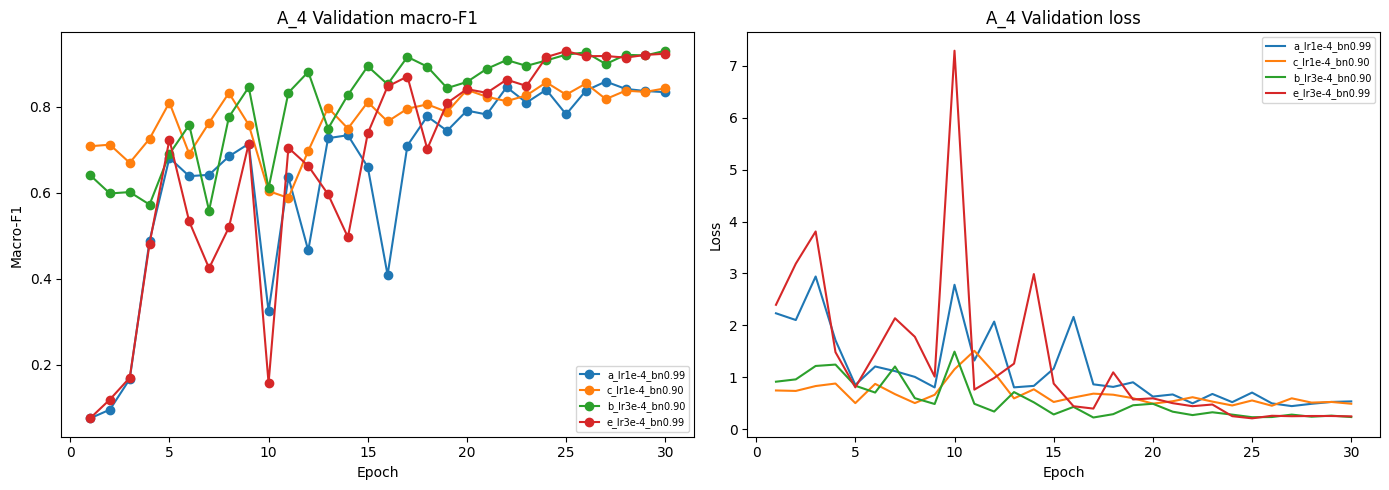

In [17]:
# ============================================================
# A_4 / CELL 3 - COMPLETE SCRATCH 2x2 GRID, FIXED 30 EPOCHS
# ============================================================
import math

if RUN_FINAL_TEST or RUN_TRAINING or RUN_REAL_HOLDOUT or not DIAGNOSTIC_ONLY:
    raise RuntimeError("A_4 requires diagnostic mode with legacy training/Test/Holdout disabled")
if keras.mixed_precision.global_policy().name != "float32":
    raise RuntimeError("A_4 uses float32 consistently across all arms; reset the precision policy first")

ABLATION_A4_DIR = A4_ROOT / "ablation_scratch_2x2"
ABLATION_A4_DIR.mkdir(parents=True, exist_ok=True)
A4_SEED = 42
A4_EPOCHS = 30
A4_WARMUP_EPOCHS = 3
A4_START_LR = 1e-5
A4_MIN_LR = 1e-6
A4_IMPLEMENTATION_SHA256 = "40194f2a551c1fed871c71936554b1d838435e2baf8edb994ab87906a6cad4b1"
A4_ARMS = {
    "a_lr1e-4_bn0.99": {"peak_lr": 1e-4, "bn_momentum": 0.99},
    "c_lr1e-4_bn0.90": {"peak_lr": 1e-4, "bn_momentum": 0.90},
    "b_lr3e-4_bn0.90": {"peak_lr": 3e-4, "bn_momentum": 0.90},
    "e_lr3e-4_bn0.99": {"peak_lr": 3e-4, "bn_momentum": 0.99},
}
A4_ARMS_TO_RUN = list(A4_ARMS)  # E.g. ["a_lr1e-4_bn0.99"]; same settings for all sessions.
if len(set(A4_ARMS_TO_RUN)) != len(A4_ARMS_TO_RUN) or set(A4_ARMS_TO_RUN) - set(A4_ARMS):
    raise ValueError("A4_ARMS_TO_RUN must contain unique, known arm names")
train_a4_clean_ds = make_dataset(train_paths, train_labels, seed=A4_SEED, training=False)
val_a4_clean_ds = make_dataset(val_paths, val_labels, seed=A4_SEED, training=False)
A4_STEPS_PER_EPOCH = math.ceil(len(train_paths) / BATCH_SIZE)
A4_TOTAL_STEPS = A4_EPOCHS * A4_STEPS_PER_EPOCH
if not (0 < A4_WARMUP_EPOCHS < A4_EPOCHS and len(val_paths) == len(val_labels) > 0):
    raise ValueError("Invalid schedule or empty/misaligned Validation data")

def a4_lr_at_step(step, peak_lr):
    if not 0 <= step < A4_TOTAL_STEPS:
        raise ValueError(f"LR step {step} outside [0, {A4_TOTAL_STEPS})")
    warmup_steps = A4_WARMUP_EPOCHS * A4_STEPS_PER_EPOCH
    if step < warmup_steps:
        return A4_START_LR + (peak_lr - A4_START_LR) * ((step + 1) / warmup_steps)
    decay_steps = max(1, A4_TOTAL_STEPS - warmup_steps - 1)
    progress = (step - warmup_steps) / decay_steps
    return A4_MIN_LR + 0.5 * (peak_lr - A4_MIN_LR) * (1.0 + math.cos(math.pi * progress))

def a4_json_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":")).encode()).hexdigest()

def a4_run_config(name, arm):
    return {
        "schema_version": 2, "arm": name, "seed": A4_SEED,
        "peak_lr": float(arm["peak_lr"]), "bn_momentum": float(arm["bn_momentum"]),
        "epochs": A4_EPOCHS, "warmup_epochs": A4_WARMUP_EPOCHS,
        "start_lr": A4_START_LR, "min_lr": A4_MIN_LR,
        "schedule": "batch_linear_warmup_cosine_inclusive_final_step",
        "steps_per_epoch": A4_STEPS_PER_EPOCH, "total_steps": A4_TOTAL_STEPS,
        "batch_size": BATCH_SIZE, "image_size": IMG_SIZE,
        "head_units": HEAD_UNITS, "head_dropout": HEAD_DROPOUT,
        "classes": list(CLASS_NAMES), "augmentation": AUGMENTATION_CONFIG,
        "model": "DenseNet121", "weights": None, "preprocessing": "bilinear_resize_rescale_0_1",
        "optimizer": "Adam", "beta_1": 0.9, "beta_2": 0.999, "epsilon": 1e-7,
        "loss": "sparse_categorical_crossentropy", "early_stopping": False,
        "sample_weights": False, "selection": "val_macro_f1_desc_val_loss_asc_epoch_asc",
        "dataset_revision": DIAGNOSTIC_DATA_REVISION,
        "dataset_fingerprints": {s: A4_DATA_FINGERPRINTS[s] for s in ("train", "val")},
        "split_sizes": {"train": len(train_paths), "val": len(val_paths)},
        "tensorflow": tf.__version__, "keras": getattr(keras, "__version__", "bundled"),
        "precision": keras.mixed_precision.global_policy().name,
        "replicas": int(strategy.num_replicas_in_sync),
        "devices": [tf.config.experimental.get_device_details(d).get("device_name", d.device_type)
                    for d in tf.config.list_physical_devices("GPU")] or ["CPU"],
        "implementation_sha256": A4_IMPLEMENTATION_SHA256,
    }

def a4_completed_summary(name, config):
    arm_dir = ABLATION_A4_DIR / name
    summary_path = arm_dir / "summary.json"
    if not summary_path.exists():
        return None
    expected = a4_run_config(name, config)
    config_path = arm_dir / "run_config.json"
    if not config_path.is_file() or json.loads(config_path.read_text(encoding="utf-8")) != expected:
        raise ValueError(f"Saved configuration/data differs for {name}; inspect/move its output directory")
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
    required = ["history.csv", "lr_batch_log.csv", "best_val_macro_f1.weights.h5",
                "best_val_loss.weights.h5", "best_val_predictions.csv"]
    if any(not (arm_dir / f).is_file() for f in required):
        raise ValueError(f"Incomplete artifacts for {name}; cannot skip this arm")
    hist = pd.read_csv(arm_dir / "history.csv")
    trace = pd.read_csv(arm_dir / "lr_batch_log.csv")
    if (summary.get("config_sha256") != a4_json_hash(expected)
            or not summary.get("schedule_completed") or summary.get("epochs_run") != A4_EPOCHS
            or hist["epoch"].tolist() != list(range(1, A4_EPOCHS + 1))
            or trace["global_step"].tolist() != list(range(A4_TOTAL_STEPS))):
        raise ValueError(f"Incomplete/inconsistent schedule for {name}")
    scheduled = np.array([a4_lr_at_step(s, config["peak_lr"]) for s in range(A4_TOTAL_STEPS)])
    if not np.allclose(trace["lr"], scheduled, rtol=1e-6, atol=1e-12):
        raise ValueError(f"Saved optimizer LR trace differs from the schedule for {name}")
    return summary

def build_a4_scratch(seed, bn_momentum):
    set_global_seed(seed)
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="image")
    x = build_data_augmentation(seed)(inputs)
    x = layers.Rescaling(1.0 / 255.0, name="rescale_0_1")(x)
    backbone = tf.keras.applications.DenseNet121(include_top=False, weights=None,
        input_shape=(IMG_SIZE, IMG_SIZE, 3), name="densenet121_backbone")
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.momentum = bn_momentum
    x = backbone(x)
    x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
    x = layers.Dense(HEAD_UNITS, activation="relu", name="classifier_dense")(x)
    x = layers.BatchNormalization(momentum=bn_momentum, name="classifier_bn")(x)
    x = layers.Dropout(HEAD_DROPOUT, seed=seed + 6, name="classifier_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)
    return keras.Model(inputs, outputs, name=f"DenseNet121_A4_seed{seed}_bn{bn_momentum}")

def run_a4_arm(name, config):
    completed = a4_completed_summary(name, config)
    if completed is not None:
        print(f"Skipping verified completed arm: {name}")
        return completed
    arm_dir = ABLATION_A4_DIR / name
    if arm_dir.exists() and any(arm_dir.iterdir()):
        raise FileExistsError(f"Partial output exists for {name}; inspect/move {arm_dir} before restarting")
    arm_dir.mkdir(parents=True, exist_ok=True)
    run_config = a4_run_config(name, config)
    (arm_dir / "run_config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")
    tf.keras.backend.clear_session()
    gc.collect()
    set_global_seed(A4_SEED)
    with strategy.scope():
        model = build_a4_scratch(A4_SEED, config["bn_momentum"])
        model.compile(optimizer=keras.optimizers.Adam(learning_rate=A4_START_LR,
                      beta_1=0.9, beta_2=0.999, epsilon=1e-7),
                      loss=keras.losses.SparseCategoricalCrossentropy(), metrics=["accuracy"],
                      steps_per_execution=1, jit_compile=False)

    class A4Audit(keras.callbacks.Callback):
        def __init__(self):
            super().__init__()
            self.rows, self.lr_rows = [], []
            self.step, self.epoch_no = 0, 0
            self.best_f1, self.best_loss = -1.0, float("inf")

        def on_epoch_begin(self, epoch, logs=None):
            self.epoch_no = epoch + 1

        def on_train_batch_begin(self, batch, logs=None):
            iteration = int(self.model.optimizer.iterations.numpy())
            if iteration != self.step:
                raise RuntimeError("Optimizer iteration and schedule step disagree")
            requested = a4_lr_at_step(self.step, config["peak_lr"])
            self.model.optimizer.learning_rate.assign(requested)
            actual = float(self.model.optimizer.learning_rate.numpy())
            if not np.isclose(actual, requested, rtol=1e-6, atol=1e-12):
                raise RuntimeError("Optimizer did not apply the requested LR")
            self.lr_rows.append({"epoch": self.epoch_no, "batch": int(batch + 1),
                "global_step": self.step, "optimizer_iteration": iteration,
                "lr_requested": float(requested), "lr": actual})

        def on_train_batch_end(self, batch, logs=None):
            self.step += 1
            if int(self.model.optimizer.iterations.numpy()) != self.step:
                raise RuntimeError("Expected one optimizer update per batch")

        def on_epoch_end(self, epoch, logs=None):
            logs = logs or {}
            if self.step != (epoch + 1) * A4_STEPS_PER_EPOCH:
                raise RuntimeError("Dataset cardinality does not match scheduled batches")
            train_eval = self.model.evaluate(train_a4_clean_ds, return_dict=True, verbose=0)
            probs = self.model.predict(val_a4_clean_ds, verbose=0)
            if probs.shape != (len(val_labels), NUM_CLASSES) or not np.isfinite(probs).all():
                raise RuntimeError("Invalid Validation predictions")
            pred = np.argmax(probs, axis=1)
            macro_f1 = float(f1_score(val_labels, pred, average="macro",
                                    labels=np.arange(NUM_CLASSES), zero_division=0))
            lrs = [r["lr"] for r in self.lr_rows if r["epoch"] == epoch + 1]
            row = {"epoch": int(epoch + 1), "lr_first_batch": lrs[0], "lr_last_batch": lrs[-1],
                "lr_min": min(lrs), "lr_max": max(lrs),
                "train_online_accuracy": float(logs["accuracy"]), "train_online_loss": float(logs["loss"]),
                "train_inference_accuracy": float(train_eval["accuracy"]),
                "train_inference_loss": float(train_eval["loss"]),
                "val_accuracy": float(logs["val_accuracy"]), "val_loss": float(logs["val_loss"]),
                "val_macro_f1": macro_f1}
            if not np.isfinite(list(row.values())).all():
                raise RuntimeError("Non-finite training/Validation metric; arm is incomplete")
            self.rows.append(row)
            pd.DataFrame(self.rows).to_csv(arm_dir / "history.csv", index=False)
            pd.DataFrame(self.lr_rows).to_csv(arm_dir / "lr_batch_log.csv", index=False)
            if macro_f1 > self.best_f1 or (macro_f1 == self.best_f1 and row["val_loss"] < self.best_loss):
                self.best_f1, self.best_loss = macro_f1, row["val_loss"]
                self.model.save_weights(arm_dir / "best_val_macro_f1.weights.h5")
                predictions = pd.DataFrame({"path": val_paths, "label": val_labels,
                                            "prediction": pred, "selected_epoch": epoch + 1})
                for c, class_name in enumerate(CLASS_NAMES):
                    predictions[f"prob_{class_name}"] = probs[:, c]
                predictions.to_csv(arm_dir / "best_val_predictions.csv", index=False)
            print(f"{name} epoch {epoch+1}/{A4_EPOCHS}: val_macro_f1={macro_f1:.4f}, val_loss={row['val_loss']:.4f}")

    audit = A4Audit()
    loss_checkpoint = keras.callbacks.ModelCheckpoint(filepath=str(arm_dir / "best_val_loss.weights.h5"),
        monitor="val_loss", mode="min", save_best_only=True, save_weights_only=True, verbose=0)
    model.fit(make_dataset(train_paths, train_labels, seed=A4_SEED, training=True),
        validation_data=val_a4_clean_ds, epochs=A4_EPOCHS, callbacks=[audit, loss_checkpoint], verbose=1)
    hist = pd.DataFrame(audit.rows)
    if len(hist) != A4_EPOCHS or audit.step != A4_TOTAL_STEPS:
        raise RuntimeError("Arm stopped before completing the schedule; no completed summary written")
    best = hist.sort_values(["val_macro_f1", "val_loss", "epoch"], ascending=[False, True, True]).iloc[0]
    summary = {"arm": name, "seed": A4_SEED, "epochs_run": len(hist), "schedule_completed": True,
        "optimizer_steps": audit.step, "lr_final": audit.lr_rows[-1]["lr"],
        "best_epoch": int(best["epoch"]), "best_val_macro_f1": float(best["val_macro_f1"]),
        "val_accuracy_at_best": float(best["val_accuracy"]), "val_loss_at_best": float(best["val_loss"]),
        "peak_lr": float(config["peak_lr"]), "bn_momentum": float(config["bn_momentum"]),
        "early_stopping": False, "selection_metric": "clean_validation_macro_f1",
        "tie_break": "lower_validation_loss_then_earlier_epoch", "test_used_for_selection": False,
        "selected_checkpoint": "best_val_macro_f1.weights.h5",
        "dataset_revision": DIAGNOSTIC_DATA_REVISION, "config_sha256": a4_json_hash(run_config)}
    (arm_dir / "summary.md").write_text("# A_4 scratch arm - " + name + "\n\n```json\n" +
        json.dumps(summary, indent=2) + "\n```\n\n## Epoch history\n\n```csv\n" +
        hist.to_csv(index=False) + "```\n", encoding="utf-8")
    # The completion marker is written last; interrupted runs cannot be silently reused.
    temp_summary = arm_dir / "summary.json.tmp"
    temp_summary.write_text(json.dumps(summary, indent=2), encoding="utf-8")
    temp_summary.replace(arm_dir / "summary.json")
    del model
    tf.keras.backend.clear_session()
    gc.collect()
    return summary

# Check old completed outputs before starting a potentially long training job.
for arm_name, arm_config in A4_ARMS.items():
    a4_completed_summary(arm_name, arm_config)
print("A_4 active settings:", {"seed": A4_SEED, "epochs": A4_EPOCHS, "warmup": A4_WARMUP_EPOCHS,
    "batch_size": BATCH_SIZE, "steps_per_epoch": A4_STEPS_PER_EPOCH,
    "total_steps": A4_TOTAL_STEPS, "arms_to_run": A4_ARMS_TO_RUN})
for arm_name in A4_ARMS_TO_RUN:
    run_a4_arm(arm_name, A4_ARMS[arm_name])
completed = [s for name, arm in A4_ARMS.items() if (s := a4_completed_summary(name, arm)) is not None]
if completed:
    comparison = pd.DataFrame(completed).sort_values(
        ["best_val_macro_f1", "val_loss_at_best"], ascending=[False, True])
    comparison.to_csv(ABLATION_A4_DIR / "ablation_comparison.csv", index=False)
    display(comparison)
    print(f"Completed {len(completed)}/{len(A4_ARMS)} arms; compare the full grid after all four finish.")
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for result in completed:
        name = result["arm"]
        hist = pd.read_csv(ABLATION_A4_DIR / name / "history.csv")
        axes[0].plot(hist["epoch"], hist["val_macro_f1"], marker="o", label=name)
        axes[1].plot(hist["epoch"], hist["val_loss"], label=name)
    axes[0].set(title="A_4 Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
    axes[1].set(title="A_4 Validation loss", xlabel="Epoch", ylabel="Loss")
    for ax in axes:
        ax.legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(ABLATION_A4_DIR / "ablation_curves.png", dpi=160)
    plt.show()
